In [1]:
# Team: PENDING actual team names and student IDs; do not submit these placeholders.
# Execution: all cells completed on 2026-11-12. Original runs: 6/6 at 100,000. Guided runs: 6/6 evaluated at 10,000.
# Third-party implementations: https://github.com/Farama-Foundation/Gymnasium/blob/v1.4.0/gymnasium/wrappers/atari_preprocessing.py ; guidance: https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html

# CS4287 Assignment 2: Atari Pong — DQN versus Double DQN

**Question:** under the same amount of game experience, does Double DQN improve
learning speed, final score, or consistency compared with DQN?

This notebook follows **Option 2** of `CS4287-Assign2-RL_DQN-S1AY2627-v1.docx`
(4 November 2026). The entire brief was read. It explicitly requires visible
code outputs, extensive comments, diagrams, videos, references, one contribution
paragraph per member, and an AI-use record. It permits sourced/AI-assisted code
if it is acknowledged and understood. The brief specifies groups of two or three
with different membership from Assignment 1; confirm this yourselves.

**Honesty:** the cells below read actual saved measurements. A verification run
checks engineering; it does not demonstrate learned Pong skill. A partial main
run is never labelled a completed experiment. No result is filled in for a
missing run. Team identities and human contributions are intentionally pending.
The filename contains placeholder IDs and must be adjusted to the actual team.

**How to use:** select the project's `.venv` Python 3.12 kernel and Run All.
By default this rechecks a small weight update and regenerates the analysis
from saved runs. The training cell has an explicit switch for resuming the
longer experiments. All implementation, training, resuming, evaluation, verification and video code
is contained in notebook cells. No project `.py` files are imported or required.

In [2]:
# Locate supporting results whether PyCharm starts in Assignment2 or its parent.
from pathlib import Path
import json
import sys
import os
from IPython.display import display, Markdown, Image, Video, SVG
candidates = [Path.cwd(), Path.cwd() / "Assignment2", Path.cwd() / "Pong_Assignment2", Path.cwd() / "notebook_revision"]
ROOT = next((p for p in candidates if (p / "experiment_plan.json").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook beside experiment_plan.json and its runs folder.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ["MPLCONFIGDIR"] = str(ROOT / ".matplotlib")
print("Supporting files:", ROOT)
print("Notebook Python:", sys.executable)
plan = json.loads((ROOT / "experiment_plan.json").read_text(encoding="utf-8"))
print("Declared main plan:", plan["methods"], "seeds", plan["seeds"],
      "decisions per run", plan["steps_per_run"])

Supporting files: C:\Users\tyqnn\OneDrive\Documents\ChatGPT\CS4287 Neural Computing\guided_pong\assignment
Notebook Python: C:\Users\tyqnn\PycharmProjects\PongProject\.venv\Scripts\python.exe
Declared main plan: ['dqn', 'double_dqn'] seeds [17, 29, 43] decisions per run 100000


## 1. Why reinforcement learning suits Pong

An **agent** is the player controlled by our program. An **environment** is the
game it interacts with. An **action** is a joystick/button choice. A **reward**
is feedback: scoring a point gives +1, conceding gives -1, and most frames give 0.
A **policy** is the rule used to choose actions from observations.

Pong is a sequence of decisions. Moving the paddle now changes what can happen
later. We have no labelled dataset saying which action is correct for every
image. Reinforcement learning lets the agent collect experience and learn from
consequences. Its objective is high total future reward, rather than high
classification accuracy on a set of labelled frames.

**Q(s,a)** estimates the discounted future reward from taking action `a` in
observed state `s`, then choosing good actions. Here `s` is four recent images.
A **discount factor**, gamma, gives less weight to rewards further away. Our
gamma is 0.99 per agent decision. A **Deep Q Network (DQN)** approximates Q using
a neural network. Its six outputs are values, not action probabilities.

## 2. Reproducible setup and shared settings

A **seed** initialises a random generator. Matching seeds give the two methods
the same initial network weights and reproducible random streams; they do not
force identical later trajectories once the policies differ. We use training
seeds 17, 29 and 43. Evaluation uses a separate, documented set of seeds.

The following cells define the code used in the experiments. Comments explain
the purpose of the important operations. Configuration files are saved per run
so settings cannot silently change when a run resumes. `requirements-lock.txt`
records the full installed environment; `requirements.txt` lists direct packages.

In [3]:
from __future__ import annotations
import argparse
import copy
import csv
import dataclasses
import gzip
import hashlib
import importlib.metadata
import json
import os
import pickle
import platform
import random
import shutil
import sys
import time
import traceback
from collections import deque
from dataclasses import asdict, dataclass, replace
from datetime import datetime, timezone
from pathlib import Path
import ale_py
import gymnasium as gym
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

gym.register_envs(ale_py)
def utc_now():
    return datetime.now(timezone.utc).isoformat()


def write_json(path, value):
    """Replace a small JSON file atomically, so a crash cannot leave half a file."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def append_csv(path, row):
    """Keep every measurement on disk rather than only in notebook memory."""
    path = Path(path)
    exists = path.exists() and path.stat().st_size > 0
    with path.open("a", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(row))
        if not exists:
            writer.writeheader()
        writer.writerow(row)


def append_event(folder, event, **details):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    with (folder / "events.jsonl").open("a", encoding="utf-8") as stream:
        stream.write(json.dumps({"time": utc_now(), "event": event, **details}) + "\n")

In [4]:
@dataclass
class Config:
    # A step is ONE agent decision, usually FOUR emulator frames.
    method: str = "dqn"
    seed: int = 17
    total_steps: int = 100_000
    env_id: str = "ALE/Pong-v5"
    frame_skip: int = 4
    screen_size: int = 84
    stack_size: int = 4
    sticky_probability: float = 0.25
    noop_max: int = 30
    max_episode_steps: int = 27_000
    replay_capacity: int = 20_000
    learning_starts: int = 2_000
    batch_size: int = 32
    train_frequency: int = 4
    gamma: float = 0.99
    learning_rate: float = 0.0001
    target_update_interval: int = 2_000
    epsilon_start: float = 1.0
    epsilon_end: float = 0.05
    epsilon_decay_steps: int = 80_000
    clip_rewards: bool = True
    max_grad_norm: float = 10.0
    eval_interval: int = 20_000
    eval_episodes: int = 5
    final_eval_episodes: int = 10
    eval_epsilon: float = 0.01
    checkpoint_interval: int = 10_000
    log_interval: int = 1_000
    torch_threads: int = 2
    device: str = "cpu"

    def validate(self):
        assert self.method in {"dqn", "double_dqn"}
        assert self.stack_size == 4 and self.screen_size == 84
        assert self.replay_capacity > self.stack_size + self.batch_size
        assert self.total_steps >= 1 and self.train_frequency >= 1
        assert self.eval_interval >= 1 and self.checkpoint_interval >= 1
        assert 0 <= self.sticky_probability <= 1


def seed_everything(seed, threads=2):
    """Matching seeds control initial weights; separate RNGs control sampling."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(threads)
    # We use CPU. Request deterministic operations for repeatable local recovery.
    torch.use_deterministic_algorithms(True)


def epsilon_at(step, config):
    # Express decay in game decisions, so pausing does not restart exploration.
    fraction = min(step / config.epsilon_decay_steps, 1.0)
    return config.epsilon_start + fraction * (config.epsilon_end - config.epsilon_start)

In [5]:
def system_information():
    import psutil
    packages = ("torch", "gymnasium", "ale-py", "numpy", "opencv-python-headless",
                "matplotlib", "pandas", "nbformat", "nbclient", "ipykernel",
                "imageio", "imageio-ffmpeg", "psutil")
    memory = psutil.virtual_memory()
    disk = shutil.disk_usage(Path.cwd().anchor)
    return {"time": utc_now(), "python": sys.version, "executable": sys.executable,
            "platform": platform.platform(), "logical_cpus": os.cpu_count(),
            "ram_total_gib": memory.total / 2**30, "ram_available_gib": memory.available / 2**30,
            "disk_free_gib": disk.free / 2**30,
            "cuda_available": torch.cuda.is_available(),
            "cuda_devices": [torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())],
            "xpu_available": bool(hasattr(torch, "xpu") and torch.xpu.is_available()),
            "packages": {p: importlib.metadata.version(p) for p in packages}}

# Show the machine used for training, rather than guessing its capabilities.
system_record = json.loads((ROOT / "results/system.json").read_text(encoding="utf-8"))
display(system_record)
shared_config = Config(**plan["shared_config"])
print("Shared training settings:")
display(asdict(shared_config))

{'time': '2026-11-10T16:30:22.944902+00:00',
 'python': '3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]',
 'executable': 'C:\\Users\\tyqnn\\PycharmProjects\\PongProject\\.venv\\Scripts\\python.exe',
 'platform': 'Windows-11-10.0.26200-SP0',
 'logical_cpus': 16,
 'ram_total_gib': 15.628307342529297,
 'ram_available_gib': 1.7911300659179688,
 'disk_free_gib': 197.21429443359375,
 'cuda_available': False,
 'cuda_devices': [],
 'xpu_available': False,
 'packages': {'torch': '2.15.0',
  'gymnasium': '1.4.0',
  'ale-py': '0.12.1',
  'numpy': '2.5.4',
  'opencv-python-headless': '5.0.0.93',
  'matplotlib': '3.11.2',
  'pandas': '3.1.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0',
  'ipykernel': '7.4.0',
  'imageio': '2.38.1',
  'imageio-ffmpeg': '0.8.1',
  'psutil': '7.2.2'},
 'cpu_name': '13th Gen Intel(R) Core(TM) i7-1360P',
 'physical_gpu': 'Intel(R) Iris(R) Xe Graphics',
 'gpu_driver': '32.0.101.5768'}

Shared training settings:


{'method': 'dqn',
 'seed': 17,
 'total_steps': 100000,
 'env_id': 'ALE/Pong-v5',
 'frame_skip': 4,
 'screen_size': 84,
 'stack_size': 4,
 'sticky_probability': 0.25,
 'noop_max': 30,
 'max_episode_steps': 27000,
 'replay_capacity': 20000,
 'learning_starts': 2000,
 'batch_size': 32,
 'train_frequency': 4,
 'gamma': 0.99,
 'learning_rate': 0.0001,
 'target_update_interval': 2000,
 'epsilon_start': 1.0,
 'epsilon_end': 0.05,
 'epsilon_decay_steps': 80000,
 'clip_rewards': True,
 'max_grad_norm': 10.0,
 'eval_interval': 20000,
 'eval_episodes': 5,
 'final_eval_episodes': 10,
 'eval_epsilon': 0.01,
 'checkpoint_interval': 10000,
 'log_interval': 1000,
 'torch_threads': 4,
 'device': 'cpu'}

The inspected machine has an Intel i7-1360P CPU, 16 logical processors and
about 15.6 GiB RAM. Only about 2 GiB was available initially. CUDA and XPU
availability are reported above; training uses CPU. The physical graphics
adapter is Intel Iris Xe integrated graphics, with no NVIDIA CUDA device.
Disk space was ample.
Four PyTorch threads were chosen from an actual learning-throughput pilot,
not from game scores. A smaller CNN and a 20,000-transition replay memory keep
the experiment practical. This is a resource-limited DQN comparison, not a
reproduction of the original large-scale Atari benchmark.

## 3. The environment and image preprocessing

The [official ALE Pong documentation](https://ale.farama.org/environments/pong/)
specifies RGB images of shape **210 × 160 × 3**, with byte values 0–255, and a
minimal set of six actions. We print their installed-library names below.
Pong's sideways-controller names `RIGHT`/`LEFT` correspond to paddle movement
in this game; we preserve the exact labels rather than renaming their indices.
A whole match normally ends when a player reaches 21 points. The raw match
return is points scored minus points conceded, ranging from -21 to +21.

Processing follows Gymnasium's
[AtariPreprocessing implementation](https://gymnasium.farama.org/api/wrappers/misc_wrappers/#gymnasium.wrappers.AtariPreprocessing):
random initial no-op actions (1–30), action repetition for four emulator frames,
maximum over the latest two frames to reduce flicker, greyscale conversion,
and resizing to 84 × 84. We retain the complete resized screen. We stack four
observations in chronological order, giving **4 × 84 × 84** bytes. The network
divides these bytes by 255 to obtain input values between 0 and 1.

One image shows where the ball is. Several images can show where it came from,
helping the network distinguish a ball travelling towards the paddle from one
travelling away. This makes the observed state more informative, although it
does not guarantee perfect knowledge of the emulator's hidden state.

**Timing:** the base environment has `frameskip=1`. Only AtariPreprocessing
repeats an action four times. One training step means one agent decision,
usually four emulator frames; the logs also record actual emulator frames.
Reset no-ops and evaluation interactions are recorded separately or excluded
from the training-decision budget. Both methods have the same decision budget.

**Sticky actions:** with probability 0.25 on each emulator frame, execute the
previously executed action. This introduces uncertainty, following the
evaluation motivation in [Machado et al.](https://arxiv.org/abs/1709.06009).
Our practice-game settings were smooth and deterministic; the experiment uses
this explicitly stated stochastic setting instead.

During pilot recovery tests, ALE 0.12.1's native sticky-action state did not
recover exactly in a new instance. Inspection of its
[source](https://raw.githubusercontent.com/Farama-Foundation/Arcade-Learning-Environment/v0.12.1/src/ale/environment/stella_environment.cpp)
showed that the last sticky action is outside the saved ALEState. We therefore
set native `repeat_action_probability=0.0` and implement the same per-frame
probability in the small wrapper below, saving its RNG and previous action.
This is shared by both methods. It is a custom protocol, so scores should not
be compared directly with papers using a different ALE setup.

**Episode endings:** `terminated` means the game truly finished. `truncated`
means an external limit cut it off. We reset for either, but remove the future
value only for termination. A time cutoff uses the final observed next image,
not the first image of the next match. We do not end training episodes at each
point/life loss. The decision limit is 27,000; ALE may also report its own cap.
If ALE cuts off inside an action repeat, we explicitly read its actual final
screen because the preprocessing wrapper can otherwise return its old pooling
buffer. This rare final observation uses direct greyscale resizing. An
additional check forces such a cutoff and verifies the returned screen.
See [Gymnasium's time-limit guidance](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/).

In [6]:
class StickyFrameActions(gym.Wrapper):
    """Repeat the previous action with probability p on EACH emulator frame.

    ALE 0.12.1's snapshot omits its previous sticky action. Keeping that small
    piece of state here makes mid-episode checkpoint recovery exact and visible.
    ALE's own sticky probability is therefore zero; this wrapper applies it once.
    """

    def __init__(self, env, probability):
        super().__init__(env)
        self.probability = probability
        self.rng = np.random.default_rng(0)
        self.previous_action = 0

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            self.rng = np.random.default_rng(seed + 3000)
        self.previous_action = 0
        return self.env.reset(seed=seed, options=options)

    def step(self, action):
        # This wrapper is INSIDE action repetition: sample once per raw frame.
        if self.rng.random() < self.probability:
            action = self.previous_action
        self.previous_action = int(action)
        return self.env.step(self.previous_action)


class PongEnv:
    """Official Atari preprocessing plus a transparent four-frame stack.

    The base ALE has frameskip=1. ONLY AtariPreprocessing repeats the action.
    No window is opened. rgb_array is enabled only when recording a video.
    """

    def __init__(self, config, video=False):
        self.config = config
        self.raw = gym.make(
            config.env_id,
            frameskip=1,
            repeat_action_probability=0.0,  # StickyFrameActions applies p once.
            full_action_space=False,
            render_mode="rgb_array" if video else None,
            max_episode_steps=-1,  # We apply our decision-based limit below.
        )
        self.sticky = StickyFrameActions(self.raw, config.sticky_probability)
        self.pre = gym.wrappers.AtariPreprocessing(
            self.sticky,
            noop_max=config.noop_max,
            frame_skip=config.frame_skip,
            screen_size=config.screen_size,
            terminal_on_life_loss=False,  # A point/life loss is not a whole match.
            grayscale_obs=True,
            scale_obs=False,  # Save uint8; convert to [0,1] inside the CNN.
        )
        assert self.raw.unwrapped._frameskip == 1
        self.frames = deque(maxlen=config.stack_size)
        # The deque automatically drops the oldest image when a new one arrives.
        self.episode_steps = 0
        self.action_count = self.raw.action_space.n

    def reset(self, seed=None):
        image, info = self.pre.reset(seed=seed)
        # Initially no history exists: repeat the first frame four times.
        self.frames.clear()
        self.frames.extend(image.copy() for _ in range(self.config.stack_size))
        self.episode_steps = 0
        return np.stack(self.frames), info

    def step(self, action):
        # Count actual emulator frames, including shortened terminal repeats.
        before = self.raw.unwrapped.ale.getFrameNumber()
        image, reward, terminated, truncated, info = self.pre.step(int(action))
        if truncated and not terminated:
            # AtariPreprocessing can break before refreshing its pooling buffers
            # when ALE itself truncates mid-repeat. Bootstrap from the actual
            # final screen in that rare case, rather than a stale earlier image.
            import cv2
            final_screen = self.raw.unwrapped.ale.getScreenGrayscale()
            image = cv2.resize(final_screen, (self.config.screen_size, self.config.screen_size),
                               interpolation=cv2.INTER_AREA)
        self.episode_steps += 1
        # Our limit counts decisions; the engine's own limit counts raw frames.
        truncated = bool(truncated or self.episode_steps >= self.config.max_episode_steps)
        self.frames.append(image.copy())
        info["actual_game_frames"] = self.raw.unwrapped.ale.getFrameNumber() - before
        # Return the final observation BEFORE resetting, including on truncation.
        return np.stack(self.frames), float(reward), bool(terminated), truncated, info

    def state_dict(self):
        """Save the emulator AND wrapper state for exact mid-episode recovery."""
        base = self.raw.unwrapped
        return {
            "ale": pickle.dumps(base.ale.cloneSystemState()),
            "env_rng": copy.deepcopy(base.np_random.bit_generator.state),
            "frames": list(self.frames),
            "episode_steps": self.episode_steps,
            "obs_buffer": [x.copy() for x in self.pre.obs_buffer],
            "lives": self.pre.lives,
            "game_over": self.pre.game_over,
            "sticky_rng": copy.deepcopy(self.sticky.rng.bit_generator.state),
            "previous_action": self.sticky.previous_action,
        }

    def load_state_dict(self, state):
        # Reset first so Gymnasium's OrderEnforcing wrapper knows reset occurred.
        self.reset(seed=0)
        base = self.raw.unwrapped
        base.ale.restoreSystemState(pickle.loads(state["ale"]))
        base.np_random.bit_generator.state = state["env_rng"]
        self.frames = deque((x.copy() for x in state["frames"]), maxlen=self.config.stack_size)
        self.episode_steps = state["episode_steps"]
        self.pre.obs_buffer = [x.copy() for x in state["obs_buffer"]]
        self.pre.lives = state["lives"]
        self.pre.game_over = state["game_over"]
        self.sticky.rng.bit_generator.state = state["sticky_rng"]
        self.sticky.previous_action = state["previous_action"]

    def close(self):
        self.pre.close()

Matplotlib is building the font cache; this may take a moment.


Processed shape and dtype: (4, 84, 84) uint8
Installed action names: ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']
Base frame skip: 1 ; preprocessing frame skip: 4


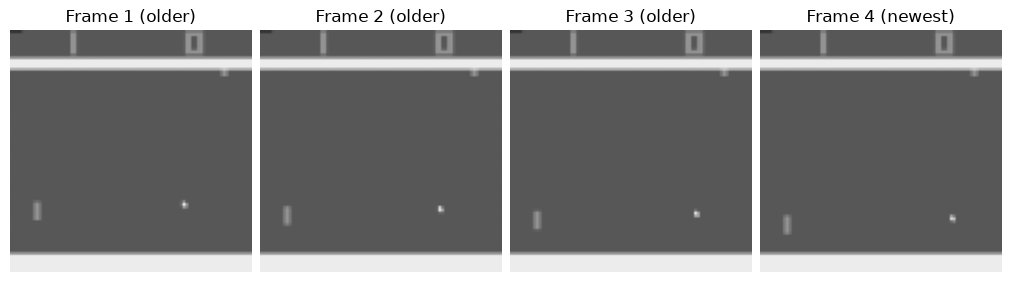

These images illustrate preprocessing; this fixed-action example is not a trained agent.


In [7]:
# Inspect real processed images without opening a game window.
import matplotlib.pyplot as plt
demonstration_env = PongEnv(shared_config)
observation, info = demonstration_env.reset(seed=808)
for _ in range(90):
    observation, _, ended, cut_off, _ = demonstration_env.step(2)
    if ended or cut_off:
        observation, info = demonstration_env.reset()
print("Processed shape and dtype:", observation.shape, observation.dtype)
print("Installed action names:", demonstration_env.raw.unwrapped.get_action_meanings())
print("Base frame skip:", demonstration_env.raw.unwrapped._frameskip,
      "; preprocessing frame skip:", demonstration_env.pre.frame_skip)
fig, axes = plt.subplots(1, 4, figsize=(10, 3), constrained_layout=True)
for i, ax in enumerate(axes):
    ax.imshow(observation[i], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Frame {i+1} ({'newest' if i==3 else 'older'})")
    ax.axis("off")
plt.show()
demonstration_env.close()
print("These images illustrate preprocessing; this fixed-action example is not a trained agent.")

## 4. CNN architecture

A **convolution** learns small image filters and reuses them across the screen.
This is useful for recognising the ball and paddles in different positions.
A **ReLU** keeps positive activations and replaces negative ones with zero,
allowing the model to learn nonlinear relationships. A **fully connected**
layer combines the extracted features into action values.

Our CNN has three convolution layers, followed by 256 hidden units and six
output units. The output has no softmax: a Q value can be negative and is not
a probability. The channels and hidden width are smaller than the canonical
Nature DQN to reduce CPU cost. Both methods use identical architecture,
optimiser and initialisation. There is no dropout, weight decay, prioritised
replay, duelling head or other modification that could confuse the comparison.
The DQN background is [Mnih et al. (2015)](https://doi.org/10.1038/nature14236).

In [8]:
class QNetwork(nn.Module):
    """Small CPU-friendly CNN. Both methods use this exact architecture."""

    def __init__(self, action_count=6):
        super().__init__()
        # Four chronological images enter as channels, not as four batch items.
        self.features = nn.Sequential(
            nn.Conv2d(4, 16, kernel_size=8, stride=4), nn.ReLU(),  # 16 x 20 x 20
            nn.Conv2d(16, 32, kernel_size=4, stride=2), nn.ReLU(),  # 32 x 9 x 9
            nn.Conv2d(32, 32, kernel_size=3, stride=1), nn.ReLU(),  # 32 x 7 x 7
            nn.Flatten(),
        )
        self.values = nn.Sequential(
            # Flattening preserves every feature; the dense layer combines them.
            nn.Linear(32 * 7 * 7, 256), nn.ReLU(),
            nn.Linear(256, action_count),  # One value for each action; no softmax.
        )

    def forward(self, images):
        images = images.float() / 255.0
        return self.values(self.features(images))

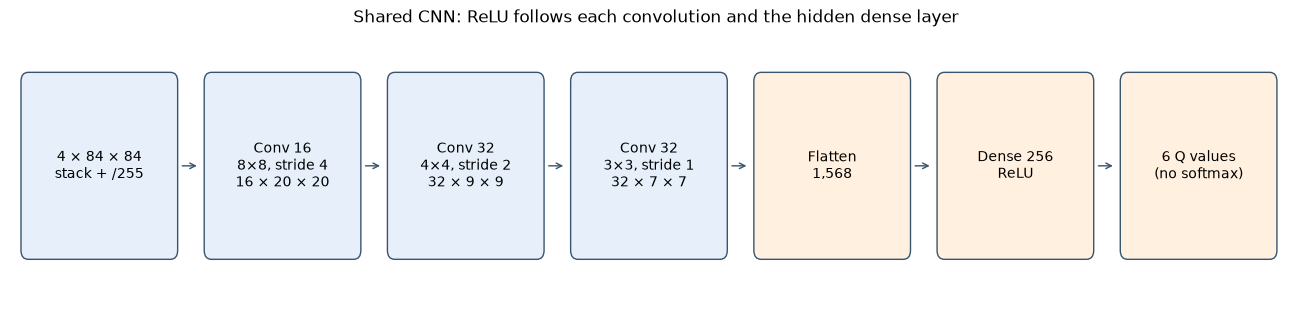

QNetwork(
  (features): Sequential(
    (0): Conv2d(4, 16, kernel_size=(8, 8), stride=(4, 4))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(4, 4), stride=(2, 2))
    (3): ReLU()
    (4): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (values): Sequential(
    (0): Linear(in_features=1568, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=6, bias=True)
  )
)
Trainable parameters: 424790
Batch-of-one output shape: (1, 6)


In [9]:
# An original diagram of THIS network, with tensor sizes after every layer.
from matplotlib.patches import FancyBboxPatch
diagram_labels = ["4 × 84 × 84\nstack + /255", "Conv 16\n8×8, stride 4\n16 × 20 × 20",
                  "Conv 32\n4×4, stride 2\n32 × 9 × 9", "Conv 32\n3×3, stride 1\n32 × 7 × 7",
                  "Flatten\n1,568", "Dense 256\nReLU", "6 Q values\n(no softmax)"]
fig, ax = plt.subplots(figsize=(13, 3), constrained_layout=True)
for i, label in enumerate(diagram_labels):
    x = i * 2.0
    ax.add_patch(FancyBboxPatch((x, .45), 1.55, 1.5, boxstyle="round,pad=.08",
                                facecolor="#e7f0fa" if i < 4 else "#fff0df",
                                edgecolor="#38546e"))
    ax.text(x+.775, 1.2, label, ha="center", va="center", fontsize=10)
    if i < len(diagram_labels)-1:
        ax.annotate("", xy=(x+1.87, 1.2), xytext=(x+1.65, 1.2),
                    arrowprops={"arrowstyle": "->", "color": "#38546e"})
ax.set(xlim=(-.2, 13.9), ylim=(0, 2.4))
ax.axis("off")
ax.set_title("Shared CNN: ReLU follows each convolution and the hidden dense layer")
fig.savefig(ROOT / "results/network_diagram.png", dpi=170)
plt.show()
example_network = QNetwork(6)
print(example_network)
print("Trainable parameters:", sum(p.numel() for p in example_network.parameters()))
print("Batch-of-one output shape:", tuple(example_network(torch.zeros(1,4,84,84,dtype=torch.uint8)).shape))

## 5. Collecting and sampling experiences

An **experience** or **transition** is `(state, action, reward, next_state,
terminated, truncated)`. The agent collects one transition per decision.
**Experience replay** stores recent transitions and samples a random
**mini-batch** (a small group) for each learning update. This reuses experience
and reduces the strong similarity between immediately adjacent training samples.

Our replay buffer holds 20,000 transitions, overwriting the oldest when full.
Naively storing both four-frame stacks would take about 1.05 GiB. We instead
save the current last frame and the next frame per transition: about 269 MiB
for image arrays. Previous frames reconstruct the rest of the stack. Episode
counters prevent joining frames from different matches; absolute IDs detect
overwritten history. The oldest three transitions are excluded after the
ring wraps because their earlier history may have been overwritten. This is
uniform sampling with replacement among the remaining valid entries.

**Epsilon-greedy exploration** chooses a uniformly random action with
probability epsilon; otherwise it chooses the action with largest online Q.
Epsilon falls linearly from 1.0 to 0.05 over 80,000 training decisions. Random
actions help collect varied experience. The first 2,000 decisions fill replay
before learning begins; thereafter one batch of 32 is learned every four
decisions. Rewards are clipped to their sign for training. Pong already has
unit point rewards, so this normally does not change them. Evaluation always
sums original rewards over a whole match.

In [10]:
class ReplayBuffer:
    """Uniform replay storing two uint8 frames per transition instead of 8.

    Consecutive states share most images. We reconstruct a current stack from
    the previous three transitions; next_stack = current_stack[1:] + next_frame.
    episode_steps prevents histories crossing resets. Absolute IDs prevent
    accidentally reading overwritten entries after the circular buffer wraps.
    """

    def __init__(self, capacity, seed, screen_size=84):
        self.capacity = capacity
        # Byte images take one quarter the space of float32 images.
        self.frames = np.zeros((capacity, screen_size, screen_size), dtype=np.uint8)
        self.next_frames = np.zeros_like(self.frames)
        self.actions = np.zeros(capacity, dtype=np.int64)
        self.rewards = np.zeros(capacity, dtype=np.float32)
        # Store both ending flags: they have different meanings for bootstrapping.
        self.terminated = np.zeros(capacity, dtype=np.bool_)
        self.truncated = np.zeros(capacity, dtype=np.bool_)
        self.episode_steps = np.zeros(capacity, dtype=np.int64)
        self.ids = np.full(capacity, -1, dtype=np.int64)
        self.count = 0
        self.rng = np.random.default_rng(seed)

    def __len__(self):
        return min(self.count, self.capacity)

    def add(self, state, action, reward, next_state, terminated, truncated, episode_step):
        # Modulo implements a ring: new transitions replace the oldest slots.
        i = self.count % self.capacity
        self.frames[i] = state[-1]
        self.next_frames[i] = next_state[-1]
        self.actions[i] = action
        self.rewards[i] = reward
        self.terminated[i] = terminated
        self.truncated[i] = truncated
        self.episode_steps[i] = episode_step
        self.ids[i] = self.count
        # IDs keep increasing even after the physical storage index wraps.
        self.count += 1

    def sample(self, batch_size):
        # Once full, omit the oldest three entries whose history was overwritten.
        oldest = max(0, self.count - self.capacity)
        start = oldest + (3 if oldest > 0 else 0)
        absolute_ids = self.rng.integers(start, self.count, size=batch_size)
        # Sampling with replacement allows a transition to occur twice in a batch.
        slots = absolute_ids % self.capacity
        stacks = []
        for offset in (3, 2, 1, 0):
            # At the beginning of an episode, pad with that episode's first frame.
            previous_ids = absolute_ids - np.minimum(offset, self.episode_steps[slots])
            history_slots = previous_ids % self.capacity
            assert np.array_equal(self.ids[history_slots], previous_ids)
            stacks.append(self.frames[history_slots])
        states = np.stack(stacks, axis=1)
        # Shift history by one image, then append the actual next image.
        next_states = np.concatenate((states[:, 1:], self.next_frames[slots, None]), axis=1)
        return {
            "states": states, "next_states": next_states, "slots": slots,
            "actions": self.actions[slots], "rewards": self.rewards[slots],
            "terminated": self.terminated[slots], "truncated": self.truncated[slots],
        }

    def state_dict(self):
        # Copy only populated slots until the circular buffer is full.
        n = len(self)
        names = ("frames", "next_frames", "actions", "rewards", "terminated",
                 "truncated", "episode_steps", "ids")
        return {"count": self.count, "rng": self.rng.bit_generator.state,
                "arrays": {name: getattr(self, name)[:n] for name in names}}

    def load_state_dict(self, state):
        self.count = state["count"]
        # Restoring the generator state restores the future sequence of batches.
        self.rng.bit_generator.state = state["rng"]
        for name, array in state["arrays"].items():
            getattr(self, name)[:len(array)] = array


@torch.inference_mode()
def choose_action(network, observation, epsilon, rng, action_count, device="cpu"):
    # Use our saved generator, not action_space.sample's independent hidden RNG.
    if rng.random() < epsilon:
        return int(rng.integers(action_count))
    image_tensor = torch.as_tensor(observation[None], device=device)
    # Add a batch dimension: [4,84,84] becomes [1,4,84,84].
    return int(network(image_tensor).argmax(dim=1).item())

## 6. Q-learning, maximisation bias and Double DQN

There are two networks in **both** methods. The **online network** chooses
actions and has its weights changed by learning. The **target network** is a
frozen copy used to calculate targets. Every 2,000 training decisions we copy
online weights into it. Frozen targets change less rapidly, making the
prediction problem more stable. Double DQN does not introduce a third network.

**Maximisation bias** means that choosing the largest of several noisy value
estimates tends to select an overly optimistic estimate. Even zero-mean errors
can create an upward bias after taking their maximum. This motivated
[Double Q-learning (van Hasselt, 2010)](https://proceedings.neurips.cc/paper/2010/hash/091d584fced301b442654dd8c23b3fc9-Abstract.html).
[Double DQN (van Hasselt, Guez and Silver, 2016)](https://arxiv.org/abs/1509.06461)
applies action selection and evaluation using the two existing DQN networks.
It can reduce overestimation; it does not guarantee a higher score in Pong.

Let `r` be reward, `gamma` the discount, `T` the true-termination flag,
`theta` the online weights and `theta_minus` the frozen target weights.

**DQN target:**
$$y = r + \gamma(1-T)\max_{a'}Q_{\theta^-}(s',a').$$

**Double DQN target:** first select
$$a^* = \operatorname{argmax}_{a'}Q_\theta(s',a'),$$
then evaluate
$$y = r + \gamma(1-T)Q_{\theta^-}(s',a^*).$$

This target calculation is the controlled modification. Double DQN uses an
extra online forward pass when calculating targets, so equal game experience
need not cost equal wall-clock time. The networks remain correlated because
one is periodically copied from the other. That limits the independence of
their estimation errors and means residual bias can remain.

In [11]:
def bootstrap_values(next_online, next_target, method):
    """The ONLY algorithmic difference between DQN and Double DQN."""
    if method == "double_dqn":
        # Online selects the action; target evaluates that selected action.
        selected_actions = next_online.argmax(dim=1, keepdim=True)
        return next_target.gather(1, selected_actions).squeeze(1)
    # DQN uses target values both to select and to evaluate the action.
    return next_target.max(dim=1).values

In [12]:
# Synthetic illustration of maximisation bias; these are NOT Pong results.
rng = np.random.default_rng(2026)
errors_for_selection = rng.normal(0, 1, size=(50000, 6))
independent_errors = rng.normal(0, 1, size=(50000, 6))
selected = errors_for_selection.argmax(axis=1)
single_estimator = errors_for_selection.max(axis=1)
double_estimator = independent_errors[np.arange(len(selected)), selected]
print("True value of every synthetic action: 0")
print("Mean after taking max of one noisy estimate:", round(single_estimator.mean(), 3))
print("Mean after independent selection/evaluation:", round(double_estimator.mean(), 3))
print("Our real online/target networks are correlated; this toy calculation does not prove Pong improvement.")

True value of every synthetic action: 0
Mean after taking max of one noisy estimate: 1.268
Mean after independent selection/evaluation: 0.001
Our real online/target networks are correlated; this toy calculation does not prove Pong improvement.


## 7. The weight update, in detail

The next cell is the exact function used during training. Read it in this order:

1. **Prepare the batch.** Each state batch has shape `[32, 4, 84, 84]`.
   Actions and rewards have shape `[32]`. Image bytes become floats and are
   scaled inside `forward`. The action indices must be integers.
2. **Make a prediction.** `online(states)` returns `[32, 6]`: six Q values for
   each experience. `gather(1, actions[:, None])` picks the value for the action
   actually recorded in each transition. `squeeze(1)` gives `[32]` predictions.
   The agent must learn about the action it took, not whichever action is now
   its favourite.
3. **Build a target.** Inside `torch.no_grad()`, compute the next-state value
   using the DQN or Double DQN rule above. Add the observed reward and the
   discounted future value. For true terminal states the multiplier is zero,
   so `y = r`. For time-limit truncation it stays one; the next state is the
   final frame before reset. A target is a temporary estimate, not a known
   correct answer supplied by a teacher.
4. **Calculate the error.** The temporal-difference (**TD**) error is
   `delta = target - prediction`. We use PyTorch's
   [SmoothL1Loss](https://docs.pytorch.org/docs/2.15/generated/torch.nn.SmoothL1Loss.html)
   with its default beta of 1. This is the Huber loss for these settings.
   For error `e = prediction - target`, the per-sample loss is
   `0.5 * e**2` when `abs(e) < 1`; otherwise it is `abs(e) - 0.5`.
   We average over the mini-batch. Large errors have a bounded slope before
   gradient clipping, making them less dominant than with squared error.
5. **Clear old gradients.** `optimizer.zero_grad(set_to_none=True)` prevents
   gradients from earlier batches accumulating unintentionally.
6. **Backpropagate.** `loss.backward()` applies the chain rule through the
   selected output, dense layers, ReLUs and convolutions. For a weight `w`,
   `dL/dw = (dL/dq) * (dq/dw)`.
   In the quadratic part, `dL/dq = prediction - target` for one sample;
   in the linear part it is +1 or -1. Batch averaging divides each sample's
   contribution by the batch size. Shared hidden weights can affect all action
   predictions, even though the loss uses only each recorded action.
7. **Change the online weights.** Clip the total gradient norm to 10, then
   `optimizer.step()` applies [Adam](https://docs.pytorch.org/docs/2.15/generated/torch.optim.Adam.html)
   at learning rate 0.0001. Adam tracks moving averages of gradients and squared
   gradients to scale updates. Its update is not simply `w -= alpha*gradient`.
   The target network is excluded from the optimiser, has gradients disabled,
   and changes only at the separate hard-copy step.

`no_grad()` is crucial: the target must stay fixed while this batch is fitted.
Otherwise the optimiser could change both sides of the equation and reduce
the reported loss without making the intended prediction correction. This is
called a **semi-gradient** update: differentiate the prediction, not the
bootstrapped target. It is still possible for Q-learning with neural networks
to be unstable. A falling loss alone does not show that the agent plays well.

In [13]:
def learning_update(online, target, optimizer, batch, config):
    """One complete Q-learning weight update; explained line by line in notebook."""
    device = torch.device(config.device)
    states = torch.as_tensor(batch["states"], device=device)
    next_states = torch.as_tensor(batch["next_states"], device=device)
    actions = torch.as_tensor(batch["actions"], device=device).long()
    # Float rewards and masks can participate in the target arithmetic.
    rewards = torch.as_tensor(batch["rewards"], device=device).float()
    terminated = torch.as_tensor(batch["terminated"], device=device).float()

    # 1. Predict Q(s,a) for the actions that were actually taken in the batch.
    predicted = online(states).gather(1, actions[:, None]).squeeze(1)
    # 2. Targets are fixed numbers during this update: do not differentiate them.
    with torch.no_grad():
        next_target = target(next_states)
        next_online = online(next_states) if config.method == "double_dqn" else None
        next_values = bootstrap_values(next_online, next_target, config.method)
        # Reset after termination OR truncation, but bootstrap after truncation.
        # A real terminal game has no future return. A time cut still has one.
        expected = rewards + config.gamma * (1.0 - terminated) * next_values

    # 3. Huber loss: quadratic near zero error, linear for unusually large errors.
    loss = F.smooth_l1_loss(predicted, expected)
    # The default reduction averages the 32 sample losses into one scalar.
    # 4. Remove gradients left over from the previous mini-batch.
    optimizer.zero_grad(set_to_none=True)
    # 5. Chain rule: calculate how each weight contributed to the prediction error.
    loss.backward()
    # 6. Limit unusually large gradients, identically for both methods.
    gradient_norm = nn.utils.clip_grad_norm_(online.parameters(), config.max_grad_norm)
    # 7. Adam uses those gradients to change ONLINE weights; target stays fixed.
    optimizer.step()
    return {"loss": float(loss.detach()), "mean_q": float(predicted.detach().mean()),
            "mean_target": float(expected.mean()),
            "mean_abs_td_error": float((predicted.detach() - expected).abs().mean()),
            "gradient_norm": float(gradient_norm)}

### A small numerical example

Use only three actions for clarity. Suppose the next-state online values are
`[1, 4, 2]` and target values are `[3, 2, 1]`. Let reward = 1, gamma = 0.9 and
current prediction = 2.2. This is a nonterminal transition.

DQN chooses the largest target value, 3: its target is `1 + 0.9*3 = 3.7`.
Double DQN selects action index 1 using online value 4, then reads target
value 2 for that action: its target is `1 + 0.9*2 = 2.8`.
The DQN error is `2.2-3.7 = -1.5`, giving Huber loss `1.5-0.5 = 1.0`.
The Double DQN error is `2.2-2.8 = -0.6`, giving loss `0.5*0.6² = 0.18`.
A lower target/loss in this example is not evidence that Double DQN is correct
about the true return; it illustrates how the formulas differ.

To see an actual weight change simply, replace the CNN by one scalar weight:
`q = w*x`, with `w=1.1`, `x=2`. For the Double DQN target, `dL/dq=-0.6` and
`dq/dw=2`, so `dL/dw=-1.2`. One **SGD** update with rate 0.1 changes `w` to
`1.1-0.1*(-1.2)=1.22`, increasing the prediction to 2.44, closer to 2.8.
This scalar example uses SGD to expose the arithmetic. The real CNN uses Adam,
a batch mean, and optional gradient clipping as shown in the implementation.

In [14]:
# Execute the arithmetic, including autograd and a real scalar optimiser step.
next_online = torch.tensor([[1., 4., 2.]])
next_target = torch.tensor([[3., 2., 1.]])
for method in ("dqn", "double_dqn"):
    y = 1. + .9 * bootstrap_values(next_online, next_target, method)
    loss = F.smooth_l1_loss(torch.tensor([2.2]), y)
    print(method, "target =", round(y.item(), 3), "Huber loss =", round(loss.item(), 3))
w = nn.Parameter(torch.tensor(1.1))
scalar_optimizer = torch.optim.SGD([w], lr=.1)
q_before = w * 2.
scalar_loss = F.smooth_l1_loss(q_before, torch.tensor(2.8))
scalar_optimizer.zero_grad()
scalar_loss.backward()
print("Scalar gradient:", round(w.grad.item(), 3))
scalar_optimizer.step()
print("Updated weight:", round(w.item(), 3), "; updated prediction:", round((w*2.).item(), 3))
# The future value vanishes only for real termination, not for a time cutoff.
print("True terminal target:", 1.)
print("Time-limit truncation target:", 1. + .9 * 2.)

dqn target = 3.7 Huber loss = 1.0
double_dqn target = 2.8 Huber loss = 0.18


Scalar gradient: -1.2
Updated weight: 1.22 ; updated prediction: 2.44
True terminal target: 1.0
Time-limit truncation target: 2.8


In [15]:
# Run a genuine CNN/Adam update and check that only online weights change.
# This is a learning-update verification, not a Pong performance experiment.
def check_targets():
    # Online prefers action 1; target prefers action 0. The methods must differ.
    online = torch.tensor([[1., 4., 2.], [1., 4., 2.]])
    target = torch.tensor([[3., 2., 1.], [3., 2., 1.]])
    assert torch.equal(bootstrap_values(online, target, "dqn"), torch.tensor([3., 3.]))
    assert torch.equal(bootstrap_values(online, target, "double_dqn"), torch.tensor([2., 2.]))
    # A time cutoff must retain the future value; a true terminal must remove it.
    rewards = torch.tensor([1., 1.])
    terminated = torch.tensor([1., 0.])
    computed = rewards + .9 * (1 - terminated) * bootstrap_values(online, target, "double_dqn")
    assert torch.allclose(computed, torch.tensor([1., 2.8]))
    return {"dqn_next_value": 3., "double_dqn_next_value": 2.,
            "terminal_target": 1., "truncation_target": 2.8}

def check_replay():
    # Deliberately tiny ring: exercise overwrite boundaries and frequent resets.
    replay = ReplayBuffer(13, 123)
    expected = {}
    state = None
    for index in range(60):
        t = index % 7
        frame = np.full((84, 84), index, np.uint8)
        state = np.repeat(frame[None], 4, axis=0) if t == 0 else next_state
        next_frame = np.full((84, 84), index + 1, np.uint8)
        next_state = np.concatenate([state[1:], next_frame[None]])
        # Use action to identify the sampled transition in this synthetic check.
        replay.add(state, index, 1., next_state, t == 6, False, t)
        expected[index] = (state.copy(), next_state.copy())
        batch = replay.sample(20)
        for j, action in enumerate(batch["actions"]):
            assert np.array_equal(batch["states"][j], expected[action][0])
            assert np.array_equal(batch["next_states"][j], expected[action][1])
    return "60 insertions; exact reconstructed stacks after resets and ring overwrite"

def check_weight_update():
    config = replace(Config(), replay_capacity=128)
    seed_everything(9)
    online = QNetwork()
    target = copy.deepcopy(online).eval()
    target.requires_grad_(False)
    optimizer = torch.optim.Adam(online.parameters(), lr=config.learning_rate)
    rng = np.random.default_rng(9)
    batch = {"states": rng.integers(0, 256, (4, 4, 84, 84), dtype=np.uint8),
             "next_states": rng.integers(0, 256, (4, 4, 84, 84), dtype=np.uint8),
             "actions": np.array([0, 1, 2, 3]), "rewards": np.array([1., -1., 0., 1.]),
             "terminated": np.array([True, False, False, True]),
             "truncated": np.array([False, True, False, False])}
    before = {k: v.clone() for k, v in online.state_dict().items()}
    target_before = {k: v.clone() for k, v in target.state_dict().items()}
    metrics = learning_update(online, target, optimizer, batch, config)
    assert np.isfinite(metrics["loss"])
    assert any(not torch.equal(v, before[k]) for k, v in online.state_dict().items())
    assert all(torch.equal(v, target_before[k]) for k, v in target.state_dict().items())
    assert all(p.grad is None for p in target.parameters())
    return metrics
print("Equation check:", check_targets())
print("Replay reset/overwrite check:", check_replay())
display(check_weight_update())
verification = json.loads((ROOT / "results/verification.json").read_text(encoding="utf-8"))
print("Saved pilot verification (including exact recovery):")
display(verification)

Equation check: {'dqn_next_value': 3.0, 'double_dqn_next_value': 2.0, 'terminal_target': 1.0, 'truncation_target': 2.8}


Replay reset/overwrite check: 60 insertions; exact reconstructed stacks after resets and ring overwrite


{'loss': 0.37538591027259827,
 'mean_q': -0.03411038592457771,
 'mean_target': 0.2568318545818329,
 'mean_abs_td_error': 0.7581947445869446,
 'gradient_norm': 0.5691384077072144}

Saved pilot verification (including exact recovery):


{'target_equations': {'dqn_next_value': 3.0,
  'double_dqn_next_value': 2.0,
  'terminal_target': 1.0,
  'truncation_target': 2.8},
 'replay': '60 insertions; exact reconstructed stacks after resets and ring overwrite',
 'learning_update': {'loss': 0.37538591027259827,
  'mean_q': -0.03411038592457771,
  'mean_target': 0.2568318545818329,
  'mean_abs_td_error': 0.7581947445869446,
  'gradient_norm': 0.5691384077072144},
 'environment': {'shape': [4, 84, 84],
  'dtype': 'uint8',
  'actions': ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE'],
  'base_frameskip': 1,
  'wrapper_frameskip': 4,
  'exact_environment_recovery': True,
  'external_truncation': True},
 'full_recovery': {'saved_step': 160,
  'compared_step': 240,
  'identical_pixels_rewards_and_weights': True,
  'updates': 45},
 'mid_repeat_truncation': 'Raw cutoff during action repeat bootstraps from exact final screen'}

In [16]:
def check_environment():
    config = Config()
    env = PongEnv(config)
    try:
        state, _ = env.reset(seed=7)
        assert state.shape == (4, 84, 84) and state.dtype == np.uint8
        for _ in range(30):
            env.step(2)
        saved = env.state_dict()
        continuation = [env.step(a) for a in [2, 3, 1, 0, 2, 3]]
        env.load_state_dict(saved)
        repeated = [env.step(a) for a in [2, 3, 1, 0, 2, 3]]
        for left, right in zip(continuation, repeated):
            assert np.array_equal(left[0], right[0])
            assert left[1:4] == right[1:4]
        # Confirm our external limit returns truncated rather than terminated.
        limited = PongEnv(replace(config, max_episode_steps=2))
        limited.reset(seed=7)
        limited.step(0)
        _, _, terminated, truncated, _ = limited.step(0)
        limited.close()
        assert truncated and not terminated
        return {"shape": list(state.shape), "dtype": str(state.dtype),
                "actions": env.raw.unwrapped.get_action_meanings(),
                "base_frameskip": env.raw.unwrapped._frameskip,
                "wrapper_frameskip": env.pre.frame_skip,
                "exact_environment_recovery": True, "external_truncation": True}
    finally:
        env.close()

def check_full_recovery():
    config = replace(Config(), total_steps=320, replay_capacity=256,
                     learning_starts=64, epsilon_decay_steps=300)
    folder = ROOT / "runs" / "pilot" / "recovery"
    trainer = Trainer(config, folder)
    trainer.advance(160)
    trainer.save()
    trainer.advance(80)
    expected = {k: v.clone() for k, v in trainer.online.state_dict().items()}
    observation = trainer.observation.copy()
    rewards = trainer.episode_return
    updates = trainer.updates
    trainer.close()
    restored = Trainer(config, folder)
    try:
        restored.load()
        assert restored.step == 160
        restored.advance(80)
        assert restored.updates == updates
        assert restored.episode_return == rewards
        assert np.array_equal(restored.observation, observation)
        assert all(torch.equal(v, expected[k]) for k, v in restored.online.state_dict().items())
        restored.save()
        return {"saved_step": 160, "compared_step": 240,
                "identical_pixels_rewards_and_weights": True, "updates": updates}
    finally:
        restored.close()

def check_mid_repeat_truncation():
    """The future-value input must be the real final screen at a raw-frame cutoff."""
    import cv2
    env = PongEnv(Config())
    try:
        env.reset(seed=77)
        for i in range(120):
            env.step(i % 6)
        original = env.sticky.step

        def forced_cutoff(action):
            observation, reward, terminated, truncated, info = original(action)
            return observation, reward, terminated, True, info

        env.sticky.step = forced_cutoff
        state, _, terminated, truncated, _ = env.step(2)
        expected = cv2.resize(env.raw.unwrapped.ale.getScreenGrayscale(), (84, 84),
                              interpolation=cv2.INTER_AREA)
        assert truncated and not terminated
        assert np.array_equal(state[-1], expected)
        return "Raw cutoff during action repeat bootstraps from exact final screen"
    finally:
        env.close()

def benchmark():
    rows = []
    # A hardware choice, not performance tuning: no game scores select settings.
    for threads in (1, 2, 4):
        config = replace(Config(), total_steps=1400, learning_starts=128,
                         replay_capacity=2000, torch_threads=threads)
        trainer = Trainer(config, ROOT / "runs" / "pilot" / f"throughput_threads_{threads}")
        try:
            trainer.advance(400)  # Warm up CNN and optimiser before measuring.
            before_updates = trainer.updates
            started = time.perf_counter()
            trainer.advance(1000)
            seconds = time.perf_counter() - started
            trainer.save()
            row = {"threads": threads, "measured_decisions": 1000,
                   "measured_updates": trainer.updates - before_updates,
                   "elapsed_s": seconds, "decisions_per_s": 1000 / seconds,
                   "note": "Pilot only; includes actual CNN updates and environment stepping."}
            rows.append(row)
            write_json(ROOT / "results" / "throughput.json", rows)
            print(json.dumps(row), flush=True)
        finally:
            trainer.close()
    return rows

RUN_FRESH_PILOT = False  # Optional: creates fresh engineering checks, not main results.
if RUN_FRESH_PILOT:
    display(check_environment())
    display(check_full_recovery())
    display(check_mid_repeat_truncation())
    display(benchmark())
else:
    print("Saved pilot records shown above; fresh recovery and throughput checks are available in this cell.")

Saved pilot records shown above; fresh recovery and throughput checks are available in this cell.

## 8. Training, evaluation and recovery

The loop chooses an action, steps the game, saves the transition and sometimes
learns a mini-batch. We preserve raw episode scores in `episodes.csv`, sampled
update diagnostics in `updates.csv`, throughput in `progress.csv`, and each
evaluation game in `evaluations.csv`. Configuration and status JSON files
accompany every planned run, including a failed or unstarted run. JSONL event
files record exceptions and recovery. Pilot/debug runs live under `runs/pilot`
and are excluded from main performance plots.

Evaluation uses a separate environment, the online network, and fixed
**epsilon = 0.01**: 99% greedy decisions and 1% uniformly random decisions.
The RNG and starting seeds are separate from training. Periodic evaluation
uses five full games at step 0 and every 20,000 decisions; final evaluation
uses ten games at 100,000. The first five final starts match the periodic starts.
There are no optimiser steps, replay writes or training-epsilon changes during
evaluation. We report original scores and episode lengths, plus truncation flags.

Full checkpoints include both networks, Adam state, replay, current stacked
observation, in-progress episode score/length, Python/NumPy/PyTorch/action/replay
RNG states, ALE state, preprocessing buffers, and the explicit sticky-action
state. They are compressed and replaced atomically. `policy.pt` is a small
inference-only copy. Recovery tests compare continued versus restored pixels,
rewards and weights, rather than merely checking that a file can be opened.
Log rows beyond the last saved checkpoint are archived before rollback, so
a crash cannot silently count transitions twice. At most the work since the
latest checkpoint may need to be repeated after an abrupt process/power loss.

In [17]:
@torch.inference_mode()
def evaluate(network, config, step, episodes, train_elapsed_s=0.0):
    """Separate environment/RNG; raw rewards, no replay writes or weight updates."""
    env = PongEnv(config)
    # Evaluation never advances the training environment or its random streams.
    was_training = network.training
    network.eval()
    rows = []
    try:
        for index in range(episodes):
            # Reuse the same held-out starts at every checkpoint and across methods.
            eval_seed = 100_000 + config.seed * 100 + index
            rng = np.random.default_rng(eval_seed + 1_000_000)
            observation, _ = env.reset(seed=eval_seed)
            score, length, frames = 0.0, 0, 0
            started = time.perf_counter()
            terminated = truncated = False
            while not (terminated or truncated):
                action = choose_action(network, observation, config.eval_epsilon,
                                       rng, env.action_count, config.device)
                observation, reward, terminated, truncated, info = env.step(action)
                score += reward  # Original game score; NO reward clipping here.
                length += 1
                frames += info["actual_game_frames"]
            rows.append({"step": step, "eval_index": index, "eval_seed": eval_seed,
                         "score": score, "length": length, "game_frames": frames,
                         "terminated": terminated, "truncated": truncated,
                         "eval_elapsed_s": time.perf_counter() - started,
                         "train_elapsed_s": train_elapsed_s})
    finally:
        env.close()
        # Return the model to its previous mode for any subsequent training.
        network.train(was_training)
    return rows

In [18]:
class Trainer:
    """Shared training loop. Configuration differs only in method and run seed."""

    def __init__(self, config, folder):
        config.validate()
        self.config, self.folder = config, Path(folder)
        self.folder.mkdir(parents=True, exist_ok=True)
        seed_everything(config.seed, config.torch_threads)
        # Seed once at run start. Re-seeding each episode would repeat starts.
        self.env = PongEnv(config)
        self.observation, _ = self.env.reset(seed=config.seed)
        self.online = QNetwork(self.env.action_count).to(config.device)
        self.target = copy.deepcopy(self.online).eval()
        # A copy starts with identical values, but has independent tensor storage.
        self.target.requires_grad_(False)
        self.optimizer = torch.optim.Adam(self.online.parameters(), lr=config.learning_rate)
        # Only online parameters are registered with Adam; target cannot be fitted.
        self.replay = ReplayBuffer(config.replay_capacity, config.seed + 1000)
        self.action_rng = np.random.default_rng(config.seed + 2000)
        self.step = self.updates = self.episode = self.episode_length = 0
        self.episode_return = self.elapsed_s = self.eval_elapsed_s = 0.0
        self.game_frames = self.reset_frames = 0
        self.initial_evaluated = False
        self.last_eval_step = -1
        self.last_eval_episodes = 0
        write_json(self.folder / "config.json", asdict(config))

    def advance(self, decisions):
        """Collect real transitions and update every train_frequency decisions."""
        started = time.perf_counter()
        latest = None
        for _ in range(decisions):
            action = choose_action(self.online, self.observation,
                                   epsilon_at(self.step, self.config), self.action_rng,
                                   self.env.action_count, self.config.device)
            next_observation, reward, terminated, truncated, info = self.env.step(action)
            stored_reward = float(np.sign(reward)) if self.config.clip_rewards else reward
            # Keep raw reward below for episode reporting; clip only replay reward.
            self.replay.add(self.observation, action, stored_reward, next_observation,
                            terminated, truncated, self.episode_length)
            self.observation = next_observation
            self.step += 1
            self.game_frames += info["actual_game_frames"]
            self.episode_length += 1
            self.episode_return += reward
            current_elapsed = self.elapsed_s + time.perf_counter() - started
            if terminated or truncated:
                # Store the final transition above BEFORE resetting the environment.
                append_csv(self.folder / "episodes.csv", {
                    "step": self.step, "episode": self.episode,
                    "score": self.episode_return, "length": self.episode_length,
                    "terminated": terminated, "truncated": truncated,
                    "train_elapsed_s": current_elapsed, "game_frames": self.game_frames})
                self.episode += 1
                self.episode_length, self.episode_return = 0, 0.0
                self.observation, _ = self.env.reset()
                self.reset_frames += self.env.raw.unwrapped.ale.getEpisodeFrameNumber()
            if self.step >= self.config.learning_starts and self.step % self.config.train_frequency == 0:
                # Reuse experience through replay instead of learning only this step.
                batch = self.replay.sample(self.config.batch_size)
                latest = learning_update(self.online, self.target, self.optimizer, batch, self.config)
                self.updates += 1
                if self.updates % 100 == 0:
                    append_csv(self.folder / "updates.csv", {"step": self.step,
                               "update": self.updates, **latest})
            if self.step % self.config.target_update_interval == 0:
                # A hard copy, NOT a gradient update to the target network.
                self.target.load_state_dict(self.online.state_dict())
        self.elapsed_s += time.perf_counter() - started
        # Evaluation and checkpoint I/O are measured separately from training time.
        return latest

    def state_dict(self):
        # Model-only saving would lose replay, momentum, exploration and game state.
        return {"config": asdict(self.config), "step": self.step, "updates": self.updates,
                "episode": self.episode, "episode_length": self.episode_length,
                "episode_return": self.episode_return, "elapsed_s": self.elapsed_s,
                "eval_elapsed_s": self.eval_elapsed_s, "game_frames": self.game_frames,
                "reset_frames": self.reset_frames,
                "initial_evaluated": self.initial_evaluated, "last_eval_step": self.last_eval_step,
                "last_eval_episodes": self.last_eval_episodes,
                "online": self.online.state_dict(), "target": self.target.state_dict(),
                "optimizer": self.optimizer.state_dict(), "replay": self.replay.state_dict(),
                "action_rng": self.action_rng.bit_generator.state,
                "python_rng": random.getstate(), "numpy_rng": np.random.get_state(),
                "torch_rng": torch.get_rng_state(), "env": self.env.state_dict(),
                "observation": self.observation}

    def load_state_dict(self, state):
        # Budget may be extended explicitly; all other shared settings must match.
        old, new = dict(state["config"]), asdict(self.config)
        old.pop("total_steps"); new.pop("total_steps")
        if old != new:
            raise ValueError("Checkpoint settings differ. Use the saved configuration.")
        for name in ("step", "updates", "episode", "episode_length", "episode_return",
                     "elapsed_s", "eval_elapsed_s", "game_frames", "reset_frames",
                     "initial_evaluated", "last_eval_step", "last_eval_episodes"):
            setattr(self, name, state[name])
        self.online.load_state_dict(state["online"])
        self.target.load_state_dict(state["target"])
        self.optimizer.load_state_dict(state["optimizer"])
        self.replay.load_state_dict(state["replay"])
        self.action_rng.bit_generator.state = state["action_rng"]
        self.env.load_state_dict(state["env"])
        self.observation = state["observation"].copy()
        random.setstate(state["python_rng"])
        np.random.set_state(state["numpy_rng"])
        torch.set_rng_state(state["torch_rng"])

    def save(self):
        """Full replay + optimiser + RNGs + emulator, compressed and atomic."""
        started = time.perf_counter()
        temporary = self.folder / "checkpoint.tmp.gz"
        with gzip.open(temporary, "wb", compresslevel=1) as stream:
            # Compression is effective because Pong images contain large flat areas.
            torch.save(self.state_dict(), stream)
        os.replace(temporary, self.folder / "checkpoint.pt.gz")
        torch.save({"config": asdict(self.config), "step": self.step,
                    "online": self.online.state_dict()}, self.folder / "policy.pt")
        append_event(self.folder, "checkpoint_saved", step=self.step,
                     seconds=time.perf_counter() - started)

    def load(self):
        # weights_only=False is needed for our own trusted replay/RNG checkpoint.
        # Never load an unknown downloaded pickle/checkpoint with this setting.
        with gzip.open(self.folder / "checkpoint.pt.gz", "rb") as stream:
            state = torch.load(stream, map_location=self.config.device, weights_only=False)
        self.load_state_dict(state)
        # A process may die after logging but before saving. Preserve those rows
        # in an archive, then roll active logs back to the saved step.
        for name in ("episodes.csv", "updates.csv", "progress.csv", "evaluations.csv"):
            path = self.folder / name
            if path.exists():
                with path.open(newline="", encoding="utf-8") as stream:
                    rows = list(csv.DictReader(stream))
                kept = [r for r in rows if int(r["step"]) <= self.step]
                if len(kept) != len(rows):
                    shutil.copy2(path, path.with_name(path.stem + f"_before_resume_{time.time_ns()}.csv"))
                    path.unlink()
                    for row in kept:
                        append_csv(path, row)
        append_event(self.folder, "checkpoint_resumed", step=self.step)

    def evaluate_now(self, episodes):
        started = time.perf_counter()
        # Evaluation is outside advance(): there are no replay writes or updates.
        rows = evaluate(self.online, self.config, self.step, episodes, self.elapsed_s)
        # If final evaluation needs more episodes than periodic evaluation, keep
        # its first episodes and append only the extra held-out episodes.
        already = self.last_eval_episodes if self.last_eval_step == self.step else 0
        for row in rows[already:]:
            append_csv(self.folder / "evaluations.csv", row)
        self.eval_elapsed_s += time.perf_counter() - started
        self.last_eval_step, self.last_eval_episodes = self.step, episodes
        self.initial_evaluated = True
        print(f"{self.config.method} seed={self.config.seed} step={self.step:,} "
              f"evaluation={np.mean([r['score'] for r in rows]):.2f} ({episodes} games)", flush=True)

    def close(self):
        self.env.close()

In [19]:
def run_training(config, folder, stop_at=None, trainer_factory=Trainer):
    """Resume automatically. stop_at pauses work without changing the planned budget."""
    folder = Path(folder)
    saved_config = folder / "config.json"
    # A mismatched configuration requires a new run folder, protecting comparisons.
    if saved_config.exists():
        previous = json.loads(saved_config.read_text(encoding="utf-8"))
        if previous != asdict(config):
            raise ValueError("Run folder already has another config; do not mix experiments.")
    trainer = trainer_factory(config, folder)
    end = min(config.total_steps, stop_at if stop_at is not None else config.total_steps)
    status = "running"
    append_event(folder, "run_started", planned_steps=config.total_steps, session_stop=end)
    try:
        if (folder / "checkpoint.pt.gz").exists():
            # Resume absolute step counters, so schedules continue where they stopped.
            trainer.load()
        if not trainer.initial_evaluated:
            trainer.evaluate_now(config.eval_episodes)
            trainer.save()
        write_json(folder / "status.json", {"status": status, "step": trainer.step,
                                             "planned_steps": config.total_steps, "time": utc_now()})
        while trainer.step < end:
            # Stop exactly at every evaluation/checkpoint/log boundary.
            next_events = [end]
            for interval in (config.log_interval, config.eval_interval, config.checkpoint_interval):
                next_events.append((trainer.step // interval + 1) * interval)
            next_step = min(next_events)
            before, started = trainer.step, time.perf_counter()
            latest = trainer.advance(next_step - trainer.step)
            segment_seconds = time.perf_counter() - started
            append_csv(folder / "progress.csv", {
                "step": trainer.step, "updates": trainer.updates,
                "epsilon": epsilon_at(trainer.step, config),
                "train_elapsed_s": trainer.elapsed_s, "eval_elapsed_s": trainer.eval_elapsed_s,
                "decisions_per_s": (trainer.step - before) / segment_seconds,
                "game_frames": trainer.game_frames, "reset_frames": trainer.reset_frames,
                "replay_size": len(trainer.replay)})
            if trainer.step % config.eval_interval == 0 or trainer.step == config.total_steps:
                # Evaluate every planned checkpoint, including a nonmultiple budget.
                count = config.final_eval_episodes if trainer.step == config.total_steps else config.eval_episodes
                trainer.evaluate_now(count)
            if trainer.step % config.checkpoint_interval == 0 or trainer.step == end:
                trainer.save()
            write_json(folder / "status.json", {"status": "running", "step": trainer.step,
                                                 "planned_steps": config.total_steps, "time": utc_now()})
            print(f"{config.method} seed={config.seed} {trainer.step:,}/{config.total_steps:,} "
                  f"{(trainer.step-before)/segment_seconds:.1f} decisions/s "
                  f"updates={trainer.updates}", flush=True)
        if trainer.step == config.total_steps and (trainer.last_eval_step != trainer.step or
                                                   trainer.last_eval_episodes < config.final_eval_episodes):
            trainer.evaluate_now(config.final_eval_episodes)
            trainer.save()
        status = "complete" if trainer.step >= config.total_steps else "paused"
        return {"status": status, "step": trainer.step, "updates": trainer.updates,
                "train_elapsed_s": trainer.elapsed_s, "eval_elapsed_s": trainer.eval_elapsed_s}
    except BaseException as error:
        status = "interrupted" if isinstance(error, KeyboardInterrupt) else "failed"
        append_event(folder, status, step=trainer.step, error=repr(error), traceback=traceback.format_exc())
        # Preserve current in-memory training when a normal Python error/interrupt occurs.
        try:
            trainer.save()
        except BaseException:
            append_event(folder, "emergency_save_failed", traceback=traceback.format_exc())
        raise
    finally:
        write_json(folder / "status.json", {"status": status, "step": trainer.step,
                                             "planned_steps": config.total_steps, "time": utc_now()})
        trainer.close()

## 9. Pilot, declared experiment and actual execution status

The pilot tested actual environment interaction, preprocessing, CNN learning,
logs and exact checkpoint recovery. It also tested 1, 2 and 4 CPU threads,
measuring 1,000 decisions **with 250 learning updates**, after 400 warm-up
decisions. Hardware throughput selected the thread setting; no main score was
used. All pilot records and the early recovery failure are retained.

The fixed main plan uses three independent training seeds per method,
equal 100,000-decision budgets and otherwise identical settings. Runs alternate
methods across seeds and proceed in rounds to limit differences caused by
running one method only while the laptop is cool. The training estimate is
approximate: Double DQN's extra forward pass, evaluation, saving and thermal
slowdown add time. 100,000 decisions is much smaller than full Atari research
training and may be insufficient to learn Pong. Insufficient improvement is
therefore interpreted cautiously.

The primary measure is the mean raw final score for each training seed, then
the mean of these three seed means. Learning speed is the area under the
evaluation curve divided by decisions and the first evaluation checkpoint
with mean score at least zero. This threshold was fixed before the main runs.
Variation is the sample standard deviation across the three seed means.
Individual game variation is also shown. Three seeds support a descriptive
comparison, not a strong statistical significance claim.

In [20]:
# This notebook cell manages all six runs; it uses the Trainer defined above.
def execute_experiment(until=None):
    plan = json.loads((ROOT / "experiment_plan.json").read_text(encoding="utf-8"))
    budget = plan["steps_per_run"]
    end = min(budget, until if until is not None else budget)
    interval = plan["shared_config"]["eval_interval"]
    milestones = list(range(interval, end + 1, interval))
    if not milestones or milestones[-1] != end:
        milestones.append(end)
    failures = []
    for milestone_index, milestone in enumerate(milestones):
        for seed_index, seed in enumerate(plan["seeds"]):
            methods = list(plan["methods"])
            if (seed_index + milestone_index) % 2:
                methods.reverse()
            for method in methods:
                item = next(r for r in plan["runs"] if r["method"] == method and r["seed"] == seed)
                folder = ROOT / item["folder"]
                status = json.loads((folder / "status.json").read_text(encoding="utf-8"))
                if status["step"] >= milestone:
                    continue
                config = Config(**json.loads((folder / "config.json").read_text(encoding="utf-8")))
                try:
                    print(f"START {method} seed={seed} milestone={milestone}", flush=True)
                    run_training(config, folder, stop_at=milestone)
                except KeyboardInterrupt:
                    raise
                except Exception as error:
                    failures.append({"method": method, "seed": seed, "milestone": milestone,
                                     "error": repr(error), "traceback": traceback.format_exc()})
                    write_json(ROOT / "results" / "main_failures.json", failures)
                    print(f"FAILED {method} seed={seed}: {error!r}", flush=True)
    write_json(ROOT / "results" / "last_session.json", {"finished_utc": utc_now(),
               "requested_common_milestone": end, "planned_budget": budget, "failures": failures})
    if failures:
        raise RuntimeError("Some planned runs failed. Inspect main_failures.json; all folders were retained.")

In [21]:
import pandas as pd
throughput = pd.DataFrame(json.loads((ROOT / "results/throughput.json").read_text()))
display(throughput)
print("Declared plan created:", plan["created_utc"])
print("Pilot-based training-only estimate for all six runs (hours):",
      round(plan["estimated_training_hours_all_runs"], 2))
display(json.loads((ROOT / "results/pilot_development_notes.json").read_text()))
# Safe default: inspecting/Run All regenerates analysis without silently
# starting several hours of training. Set True to finish/resume the saved plan.
RUN_MAIN_TRAINING = False
# Set a number such as 40000 for a bounded round, or None for the full plan.
TRAIN_UNTIL = 100000
if RUN_MAIN_TRAINING:
    execute_experiment(TRAIN_UNTIL)  # Resumes all six runs using their saved configurations.
else:
    print("Long training not relaunched by Run All; saved run inventory follows.")

,threads,measured_decisions,measured_updates,elapsed_s,decisions_per_s,note
0,1,1000,250,16.713607,59.831489,Pilot only; includes actual CNN updates and en...
1,2,1000,250,12.636067,79.138549,Pilot only; includes actual CNN updates and en...
2,4,1000,250,10.291325,97.169217,Pilot only; includes actual CNN updates and en...


Declared plan created: 2026-11-10T16:32:43.717037+00:00
Pilot-based training-only estimate for all six runs (hours): 1.72


{'main_runs_started_at_failure': False,
 'failed_check': 'Initial exact checkpoint recovery assertion failed with ALE native sticky actions enabled; the environment continued differently after reload in a new instance.',
 'diagnosis': 'ALE 0.12.1 stella_environment.cpp stores m_player_a_action outside ALEState; ALEState::save/load does not serialize it. Whether this matters depends on the first sticky action after recovery.',
 'source': 'https://raw.githubusercontent.com/Farama-Foundation/Arcade-Learning-Environment/v0.12.1/src/ale/environment/stella_environment.cpp',
 'correction': 'Set native repeat_action_probability=0.0 and apply the same 0.25 per-frame sticky-action rule in a small Python wrapper. Save its previous action and RNG explicitly. This wrapper is shared by both methods.',
 'other_early_check': 'An AtariPreprocessing import was attempted before the dependency installation finished and raised ModuleNotFoundError for cv2. The completed installation resolved this.',
 'inter

Long training not relaunched by Run All; saved run inventory follows.


## 10. Actual results and comparison

The analysis below reads existing CSV files only. It keeps within-run game
variation separate from variation between independently trained seeds. When
runs are unfinished, it compares only the largest evaluated horizon shared by
all six runs. A partially trained policy's latest evaluation is labelled as
such; it is not substituted for the declared final 100,000-step result.

The score curve displays each seed and the method mean; shading is **one
across-seed standard deviation**, not a confidence interval. The area under
this sparsely measured curve uses straight-line interpolation, so it is only
a coarse learning-speed measure. A threshold time is interval-censored by the
evaluation spacing: we know it was observed at that checkpoint, not the exact
decision at which skill changed. `NaN` in threshold time means not observed.

    method  seed   status   step  planned_steps
       dqn    17 complete 100000         100000
double_dqn    17 complete 100000         100000
       dqn    29 complete 100000         100000
double_dqn    29 complete 100000         100000
       dqn    43 complete 100000         100000
double_dqn    43 complete 100000         100000
    method  training_seeds  mean_score  across_seed_sd  mean_episode_decisions  comparison_step  mean_auc_score
double_dqn               3  -20.966667        0.057735                   784.8           100000      -20.970000
       dqn               3  -21.000000        0.000000                   779.8           100000      -20.946667
{
  "common_evaluated_horizon": 100000,
  "planned_steps_per_run": 100000,
  "completed_main_runs": 6,
  "planned_runs": 6,
  "actual_evaluation_games": 210,
  "actual_training_decisions": 600000,
  "actual_training_games_logged": 687,
  "any_truncated_evaluation": false,
  "all_planned_runs_evaluated": true,
  "paired_score_d

,method,seed,status,trained_steps,latest_evaluation_step,latest_mean_score,within_run_game_sd,evaluation_games,mean_episode_decisions,training_seconds_to_latest_evaluation,auc_to_common_horizon,first_nonlosing_step,main_budget_complete
0,dqn,17,complete,100000,100000,-21.0,0.000000,10,802.5,1144.232474,-21.00,NaN,True
1,double_dqn,17,complete,100000,100000,-21.0,0.000000,10,760.1,1396.490347,-20.96,NaN,True
2,dqn,29,complete,100000,100000,-21.0,0.000000,10,760.2,1234.372231,-21.00,NaN,True
3,double_dqn,29,complete,100000,100000,-21.0,0.000000,10,760.2,165155.842606,-21.00,NaN,True
4,dqn,43,complete,100000,100000,-21.0,0.000000,10,776.7,1091.586574,-20.84,NaN,True
5,double_dqn,43,complete,100000,100000,-20.9,0.316228,10,834.1,1256.379291,-20.95,NaN,True


,method,training_seeds,mean_score,across_seed_sd,mean_episode_decisions,comparison_step,mean_auc_score
0,double_dqn,3,-20.966667,0.057735,784.8,100000,-20.970000
1,dqn,3,-21.000000,0.000000,779.8,100000,-20.946667


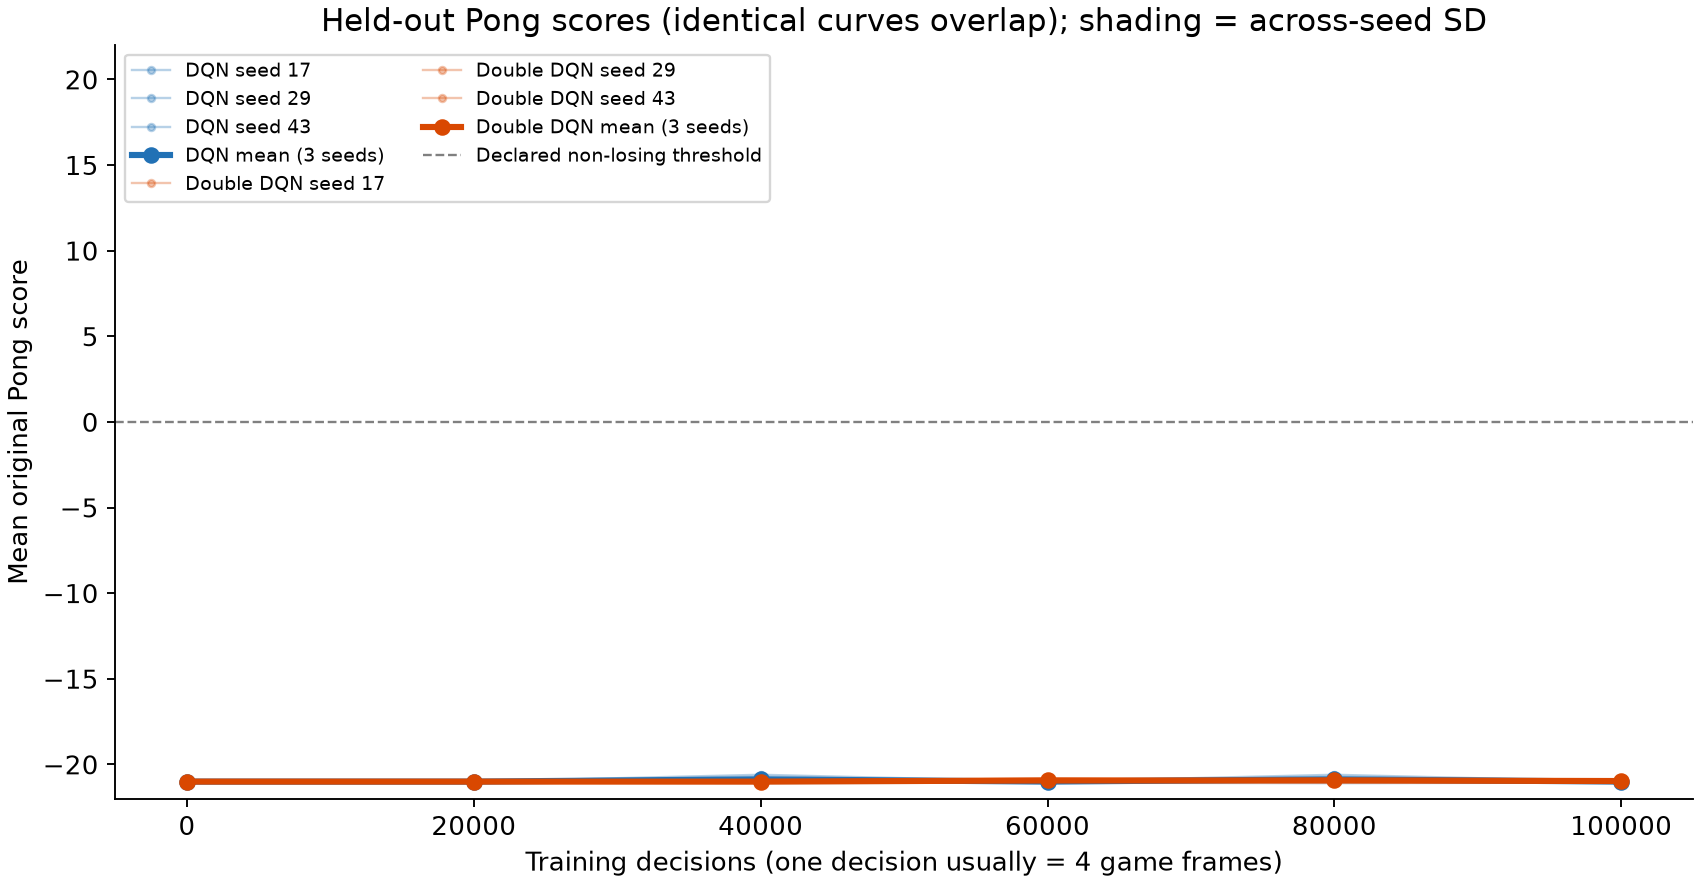

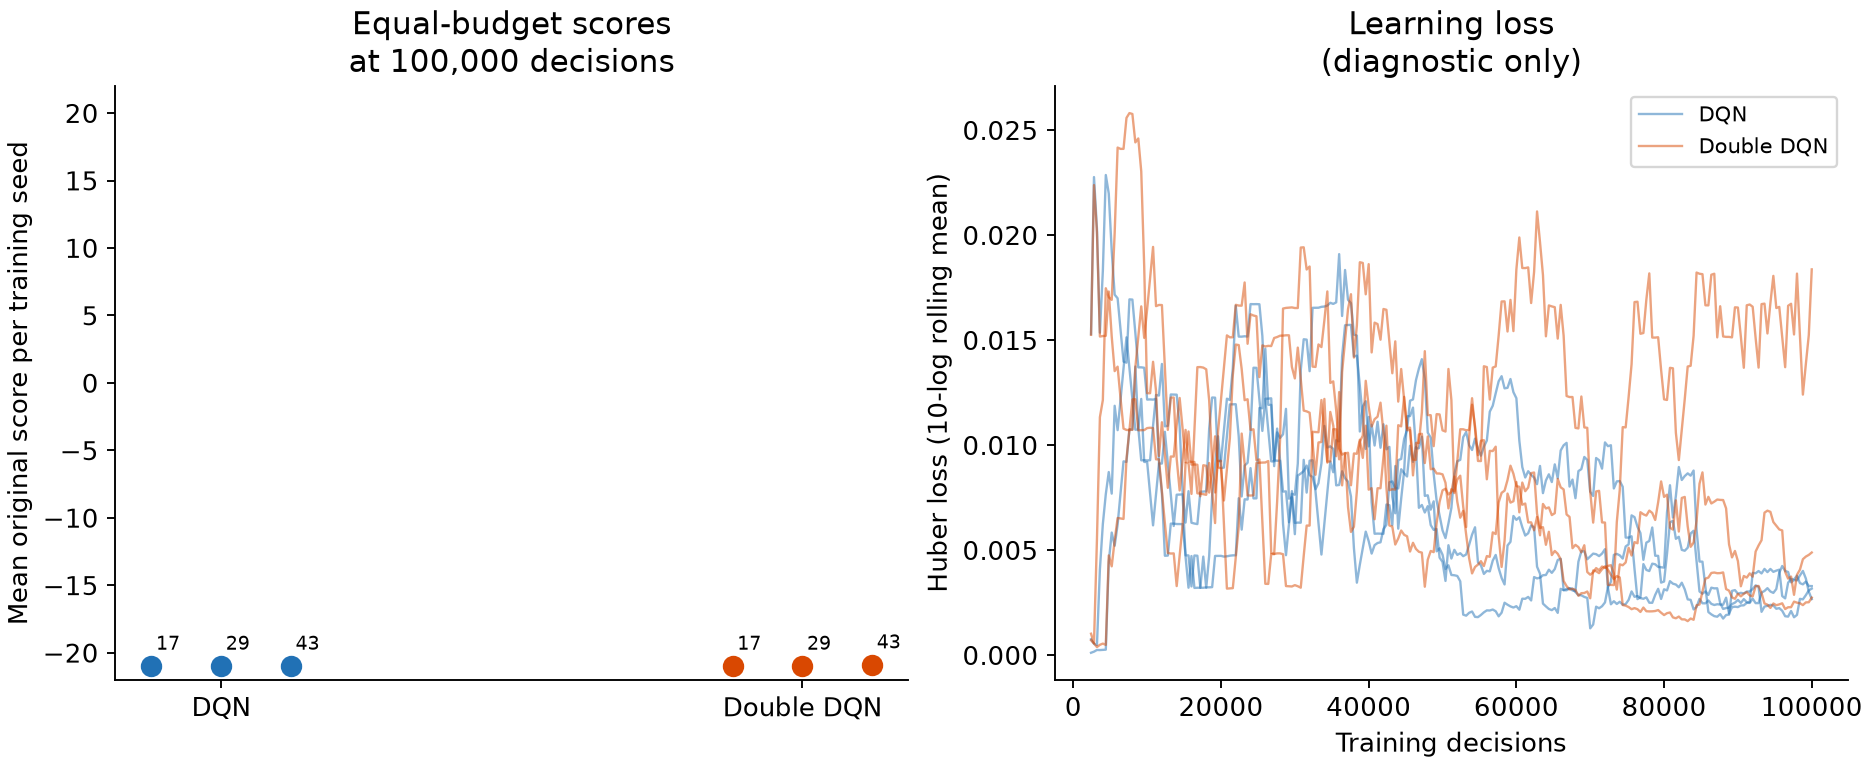

In [22]:
COLORS = {"dqn": "#2171b5", "double_dqn": "#d94801"}
LABELS = {"dqn": "DQN", "double_dqn": "Double DQN"}
def read_logs(root=ROOT):
    root = Path(root)
    plan = json.loads((root / "experiment_plan.json").read_text(encoding="utf-8"))
    evaluations, progress, updates, episodes, inventory = [], [], [], [], []
    for run in plan["runs"]:
        folder = root / run["folder"]
        status = json.loads((folder / "status.json").read_text(encoding="utf-8"))
        inventory.append({"method": run["method"], "seed": run["seed"], **status})
        for filename, collection in (("evaluations.csv", evaluations), ("progress.csv", progress),
                                     ("updates.csv", updates), ("episodes.csv", episodes)):
            path = folder / filename
            if path.exists() and path.stat().st_size:
                frame = pd.read_csv(path)
                frame["method"], frame["seed"] = run["method"], run["seed"]
                collection.append(frame)
    combine = lambda frames: pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    return plan, combine(evaluations), combine(progress), combine(updates), combine(episodes), pd.DataFrame(inventory)

def make_analysis(root=ROOT):
    root = Path(root)
    output = root / "results"
    output.mkdir(exist_ok=True)
    plan, evaluations, progress, updates, episodes, inventory = read_logs(root)
    inventory.to_csv(output / "run_inventory.csv", index=False)
    if evaluations.empty:
        raise RuntimeError("No evaluation scores exist. Run the experiment before reporting results.")
    curve = evaluations.groupby(["method", "seed", "step"], as_index=False).agg(
        mean_score=("score", "mean"), game_sd=("score", "std"), games=("score", "size"),
        mean_length=("length", "mean"), eval_train_seconds=("train_elapsed_s", "max"))
    curve.to_csv(output / "learning_curve.csv", index=False)
    observed_horizons = curve.groupby(["method", "seed"])["step"].max()
    all_evaluated = len(observed_horizons) == len(plan["runs"])
    common_horizon = int(observed_horizons.min()) if all_evaluated else 0
    per_run = []
    for run in plan["runs"]:
        method, seed = run["method"], run["seed"]
        rows = curve[(curve.method == method) & (curve.seed == seed)].sort_values("step")
        state = inventory[(inventory.method == method) & (inventory.seed == seed)].iloc[0]
        if rows.empty:
            per_run.append({"method": method, "seed": seed, "status": state["status"],
                            "trained_steps": int(state["step"]), "latest_evaluation_step": np.nan})
            continue
        latest = rows.iloc[-1]
        eligible = rows[rows.step <= common_horizon]
        crossing = eligible[eligible.mean_score >= plan["threshold"]]
        auc = (float(np.trapezoid(eligible.mean_score.to_numpy(), eligible.step.to_numpy()) / common_horizon)
               if common_horizon > 0 and len(eligible) >= 2 else np.nan)
        complete = (state["status"] == "complete" and int(latest.step) == plan["steps_per_run"]
                    and int(latest.games) >= plan["shared_config"]["final_eval_episodes"])
        per_run.append({"method": method, "seed": seed, "status": state["status"],
                        "trained_steps": int(state["step"]),
                        "latest_evaluation_step": int(latest.step),
                        "latest_mean_score": float(latest.mean_score),
                        "within_run_game_sd": float(latest.game_sd),
                        "evaluation_games": int(latest.games),
                        "mean_episode_decisions": float(latest.mean_length),
                        "training_seconds_to_latest_evaluation": float(latest.eval_train_seconds),
                        "auc_to_common_horizon": auc,
                        "first_nonlosing_step": float(crossing.step.iloc[0]) if len(crossing) else np.nan,
                        "main_budget_complete": bool(complete)})
    per_run = pd.DataFrame(per_run)
    per_run.to_csv(output / "comparison_per_seed.csv", index=False)

    # Aggregate ONLY a shared evaluated horizon; do not compare unequal endpoints.
    shared_rows = curve[curve.step == common_horizon] if common_horizon > 0 else curve.iloc[:0]
    summary = shared_rows.groupby("method", as_index=False).agg(
        training_seeds=("seed", "nunique"), mean_score=("mean_score", "mean"),
        across_seed_sd=("mean_score", "std"), mean_episode_decisions=("mean_length", "mean"))
    summary["comparison_step"] = common_horizon
    auc_by_method = per_run.groupby("method")["auc_to_common_horizon"].mean()
    summary["mean_auc_score"] = summary["method"].map(auc_by_method)
    summary.to_csv(output / "comparison_methods.csv", index=False)

    plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
    fig, ax = plt.subplots(figsize=(10, 5.2), constrained_layout=True)
    for method in plan["methods"]:
        subset = curve[curve.method == method]
        for seed, group in subset.groupby("seed"):
            ax.plot(group.step, group.mean_score, color=COLORS[method], alpha=.32,
                    linewidth=1, marker=".", label=f"{LABELS[method]} seed {seed}")
        aggregate = subset.groupby("step").mean_score.agg(["mean", "std", "count"])
        # Only draw the aggregate where all three declared seeds contributed.
        aggregate = aggregate[aggregate["count"] == len(plan["seeds"])]
        if len(aggregate):
            ax.plot(aggregate.index, aggregate["mean"], color=COLORS[method], linewidth=2.6,
                    marker="o", label=f"{LABELS[method]} mean ({len(plan['seeds'])} seeds)")
            ax.fill_between(aggregate.index, aggregate["mean"] - aggregate["std"],
                            aggregate["mean"] + aggregate["std"], color=COLORS[method], alpha=.12)
    ax.axhline(0, color="gray", linestyle="--", linewidth=1, label="Declared non-losing threshold")
    ax.set(xlabel="Training decisions (one decision usually = 4 game frames)",
           ylabel="Mean original Pong score", ylim=(-22, 22),
           title="Held-out Pong scores (identical curves overlap); shading = across-seed SD")
    ax.legend(fontsize=8, ncol=2, loc="upper left")
    fig.savefig(output / "learning_curves.png", dpi=170)
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
    for method in plan["methods"]:
        sub = shared_rows[shared_rows.method == method]
        if len(sub):
            x = plan["methods"].index(method)
            offsets = np.linspace(-.12, .12, len(sub))
            axes[0].scatter(x + offsets, sub.mean_score, color=COLORS[method], s=65)
            for offset, (_, row) in zip(offsets, sub.iterrows()):
                axes[0].annotate(str(int(row.seed)), (x+offset, row.mean_score), xytext=(2, 7),
                                 textcoords="offset points", fontsize=8)
    axes[0].set(xticks=[0, 1], xticklabels=["DQN", "Double DQN"], ylim=(-22, 22),
                ylabel="Mean original score per training seed",
                title=f"Equal-budget scores\nat {common_horizon:,} decisions")
    if not updates.empty:
        for method in plan["methods"]:
            for index, (seed, group) in enumerate(updates[updates.method == method].groupby("seed")):
                axes[1].plot(group.step, group.loss.rolling(10, min_periods=1).mean(),
                             color=COLORS[method], alpha=.5, linewidth=1,
                             label=LABELS[method] if index == 0 else None)
    axes[1].set(xlabel="Training decisions", ylabel="Huber loss (10-log rolling mean)",
                title="Learning loss\n(diagnostic only)")
    axes[1].legend(fontsize=9)
    fig.savefig(output / "scores_and_loss.png", dpi=170)
    plt.close(fig)

    total_games = len(evaluations)
    completed = int(per_run.get("main_budget_complete", pd.Series(dtype=bool)).fillna(False).sum())
    findings = {"common_evaluated_horizon": common_horizon,
                "planned_steps_per_run": plan["steps_per_run"], "completed_main_runs": completed,
                "planned_runs": len(plan["runs"]), "actual_evaluation_games": total_games,
                "actual_training_decisions": int(inventory["step"].sum()),
                "actual_training_games_logged": len(episodes),
                "any_truncated_evaluation": bool(evaluations.truncated.any()),
                "all_planned_runs_evaluated": all_evaluated}
    if len(summary) == 2:
        paired = shared_rows.pivot(index="seed", columns="method", values="mean_score")
        differences = paired["double_dqn"] - paired["dqn"]
        findings["paired_score_difference_double_minus_dqn"] = float(differences.mean())
        findings["paired_score_differences_by_seed"] = {str(k): float(v) for k, v in differences.items()}
        findings["both_methods_reached_threshold"] = bool(per_run.first_nonlosing_step.notna().all())
    write_text = json.dumps(findings, indent=2, allow_nan=False)
    (output / "findings.json").write_text(write_text, encoding="utf-8")
    print(inventory[["method", "seed", "status", "step", "planned_steps"]].to_string(index=False))
    print(summary.to_string(index=False))
    print(write_text)
    return findings, per_run, summary

findings, per_seed, method_summary = make_analysis(ROOT)
display(per_seed)
display(method_summary)
display(Image(filename=str(ROOT / "results/learning_curves.png")))
display(Image(filename=str(ROOT / "results/scores_and_loss.png")))

In [23]:
# Report status from artifacts rather than assuming training finished.
all_complete = findings["completed_main_runs"] == findings["planned_runs"]
horizon = findings["common_evaluated_horizon"]
status_text = "Completed declared main training" if all_complete else "Main training incomplete"
display(Markdown(f"**{status_text}.** {findings['completed_main_runs']}/{findings['planned_runs']} runs "
    f"have the declared final evaluation. The shared evaluated budget is **{horizon:,} decisions per run**; "
    f"the plan is {findings['planned_steps_per_run']:,}. Actual saved evaluation games: "
    f"{findings['actual_evaluation_games']}."))
if len(method_summary) == 2:
    rows = method_summary.set_index("method")
    difference = findings["paired_score_difference_double_minus_dqn"]
    display(Markdown(f"At the equal observed budget, mean scores are **DQN {rows.loc['dqn','mean_score']:.2f}** "
        f"and **Double DQN {rows.loc['double_dqn','mean_score']:.2f}**. The mean paired difference "
        f"(Double minus DQN) is **{difference:+.2f} points**. "
        f"This is {'an interim' if not all_complete else 'a budget-limited final'} observation, "
        "not evidence about what unlimited training would achieve."))
    if not per_seed["first_nonlosing_step"].notna().any():
        display(Markdown("No run has reached the declared non-losing threshold in the observed evaluations. "
            "There is no observed threshold-learning-speed winner; this does not prove equal learning ability."))
    if np.allclose(rows["mean_score"].to_numpy(), -21.):
        display(Markdown("**Both methods are at the losing-score floor (-21).** "
            "The evaluations have not demonstrated improved play. Any zero score variation here "
            "means consistently losing, rather than consistently skilled agents. "
            "Equal floor-level curves cannot establish a learning-speed or final-performance advantage."))

**Completed declared main training.** 6/6 runs have the declared final evaluation. The shared evaluated budget is **100,000 decisions per run**; the plan is 100,000. Actual saved evaluation games: 210.

At the equal observed budget, mean scores are **DQN -21.00** and **Double DQN -20.97**. The mean paired difference (Double minus DQN) is **+0.03 points**. This is a budget-limited final observation, not evidence about what unlimited training would achieve.

No run has reached the declared non-losing threshold in the observed evaluations. There is no observed threshold-learning-speed winner; this does not prove equal learning ability.

## 11. Critical evaluation

**What the measurements support.** Original game return is directly relevant:
a higher return means scoring more points relative to the opponent. Compare
both the numerical difference and seed-by-seed behaviour in the table. Similar
final scores would make earlier curve values, area under the curve and threshold
times useful, provided there was meaningful improvement. If both stay near
-21, similar results mean both performed poorly within this budget; that is
not proof that their learning speeds are equal.

**What they do not support.** Weight changes, a running game or low training
loss do not establish learned skill. If the main budget is unfinished, final
performance remains unmeasured. If final scores differ slightly across only
three seeds and ten games, the difference may reflect chance and varied starts.
No claim of statistical significance is made. A negative or inconclusive
comparison is acceptable, and must not be rewritten as a Double DQN success.

**Why familiar supervised metrics are insufficient.** Accuracy and a confusion
matrix require labelled correct actions, which we do not have. Training loss
compares one network estimate with another bootstrapped estimate. It diagnoses
the update but is not an external test of playing ability. Return, learning
curves, episode lengths and variation across seeds are more informative here.
A long episode might mean good rallies, slow loss or inactivity, so interpret
length alongside the score and video rather than rewarding length alone.

**Bias is not directly measured here.** Return comparison tests the practical
efficacy of Double DQN in this setup. Neither a lower predicted Q nor a higher
game score alone proves reduced maximisation bias. Direct bias measurement
would require suitable estimates of true returns for the same state-action
pairs, with a carefully defined future policy and uncertainty analysis. Our
synthetic example only demonstrates the mechanism under known assumptions.

**Limitations.** CPU training, small CNN, short budget and a 20,000-transition
replay buffer can constrain learning and increase forgetting. Four resized
greyscale frames lose detail. There are only three independent training seeds;
evaluation games within one seed are not independent training replications.
Repeated fixed evaluation starts improve comparisons but do not test all
possible Pong states. Final starts overlap periodic ones and no separate
validation-based tuning is performed. Sparse checkpoints can miss transient
improvements. Sticky actions are implemented explicitly for recoverability,
so this protocol differs from an untouched default ALE environment.

**Next steps.** First finish all declared runs using the exact resume command
below. Preserve these results. If further compute time is available, declare a
new longer-budget experiment for both methods before looking at its outcomes;
do not extend only the method that currently looks better. More training seeds
and an additional held-out evaluation seed set would improve uncertainty
estimates. Any new hyperparameter tuning should remain separate from final runs.

## 12. Short gameplay videos

Each video below loads a real saved policy, uses the evaluation action rule
(epsilon 0.01) and records at 15 frames per second because each displayed image
follows a four-frame decision. There is no display window. Videos are limited
to 900 decisions (about 60 seconds of game time) or the end of a match.
A clip's partial score is not a full-match evaluation score. A poor checkpoint
is labelled by its actual training step, without claiming it learned to win.
The separate fixed-action preprocessing illustration was not a policy video.

**Playback:** WebM players are embedded below. An animated GIF of the same recording is also embedded under each player as a compatibility fallback. The original MP4 remains in the videos folder. GIF previews sample every second image and preserve the approximate playback duration; they do not represent new training.

In [24]:
def prepare_playback(mp4_path):
    """Keep the original MP4; add open-codec WebM and an animated GIF fallback."""
    import subprocess
    import imageio_ffmpeg
    import imageio.v2 as imageio
    from PIL import Image as PillowImage
    mp4_path = Path(mp4_path)
    webm = mp4_path.with_suffix(".webm")
    gif = mp4_path.with_suffix(".gif")
    stale = lambda p: not p.exists() or p.stat().st_mtime < mp4_path.stat().st_mtime
    if stale(webm):
        subprocess.run([imageio_ffmpeg.get_ffmpeg_exe(), "-y", "-v", "error",
                        "-i", str(mp4_path), "-an", "-c:v", "libvpx", "-b:v", "300k",
                        "-pix_fmt", "yuv420p", str(webm)], check=True)
    if stale(gif):
        reader = imageio.get_reader(mp4_path)
        fps = reader.get_meta_data()["fps"]
        frames = []
        try:
            # Retain every second image to keep the embedded preview small.
            for index, frame in enumerate(reader):
                if index % 2 == 0:
                    frames.append(PillowImage.fromarray(frame).convert("P", palette=PillowImage.Palette.ADAPTIVE, colors=64))
        finally:
            reader.close()
        # GIF durations have 10-ms precision. Distribute rounding across frames.
        times = [round(i * 200 / fps) * 10 for i in range(len(frames) + 1)]
        durations = [times[i+1] - times[i] for i in range(len(frames))]
        frames[0].save(gif, save_all=True, append_images=frames[1:], duration=durations,
                       loop=0, optimize=False, disposal=2)
    return webm, gif


def record_video(policy_path, output, max_decisions=900, seed=900_017):
    """Record up to 60 seconds of actual checkpoint policy, not a random demo."""
    import imageio.v2 as imageio
    checkpoint = torch.load(policy_path, map_location="cpu", weights_only=False)
    config = Config(**checkpoint["config"])
    config.device = "cpu"
    seed_everything(config.seed, config.torch_threads)
    env = PongEnv(config, video=True)
    network = QNetwork(env.action_count)
    network.load_state_dict(checkpoint["online"])
    network.eval()
    rng = np.random.default_rng(seed + 1_000_000)
    observation, _ = env.reset(seed=seed)
    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    score, length = 0.0, 0
    terminated = truncated = False
    try:
        # Each rendered frame represents one four-frame decision: 15 fps at real time.
        with imageio.get_writer(output, fps=60/config.frame_skip, codec="libx264",
                                macro_block_size=2, quality=7) as writer:
            for _ in range(max_decisions):
                writer.append_data(env.raw.render())
                action = choose_action(network, observation, config.eval_epsilon,
                                       rng, env.action_count)
                observation, reward, terminated, truncated, _ = env.step(action)
                score += reward
                length += 1
                if terminated or truncated:
                    break
    finally:
        env.close()
    result = {"policy": str(Path(policy_path)), "method": config.method,
              "training_steps": checkpoint["step"], "seed": seed,
              "epsilon": config.eval_epsilon, "recorded_decisions": length,
              "partial_score": score, "episode_terminated": terminated,
              "episode_truncated": truncated, "clip_ended_early": not (terminated or truncated),
              "note": "A checkpoint policy demonstration; partial score is not a full evaluation score."}
    write_json(output.with_suffix(".json"), result)
    prepare_playback(output)  # Refresh both notebook-friendly formats.
    return result

**dqn, seed 17 — checkpoint after 100,000 decisions.** This clip shows 822 decisions; partial score -21. Observe ball returns, paddle movement and missed points; the evaluation table, not this selected clip, determines the comparison.

**Animated preview:** plays automatically and does not require a video player. It shows the same recorded gameplay at a reduced image rate.

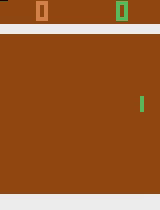

Original MP4 (open with your normal video player if needed): C:\Users\tyqnn\OneDrive\Documents\ChatGPT\CS4287 Neural Computing\guided_pong\assignment\videos\dqn_seed_17.mp4


**double_dqn, seed 17 — checkpoint after 100,000 decisions.** This clip shows 762 decisions; partial score -21. Observe ball returns, paddle movement and missed points; the evaluation table, not this selected clip, determines the comparison.

**Animated preview:** plays automatically and does not require a video player. It shows the same recorded gameplay at a reduced image rate.

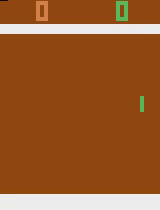

Original MP4 (open with your normal video player if needed): C:\Users\tyqnn\OneDrive\Documents\ChatGPT\CS4287 Neural Computing\guided_pong\assignment\videos\double_dqn_seed_17.mp4


In [25]:
REGENERATE_VIDEOS = False  # True records fresh clips from the current checkpoints.
# Record clips in this notebook when requested, then display the saved videos.
# WebM avoids proprietary MP4 codec requirements; GIF is a player-free fallback.
for method in ("dqn", "double_dqn"):
    path = ROOT / "videos" / f"{method}_seed_17.mp4"
    metadata_path = path.with_suffix(".json")
    policy_path = ROOT / f"runs/main/{method}_seed_17/policy.pt"
    if policy_path.exists() and (REGENERATE_VIDEOS or not path.exists()):
        record_video(policy_path, path)
    if path.exists() and metadata_path.exists():
        metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
        display(Markdown(f"**{method}, seed 17 — checkpoint after "
            f"{metadata['training_steps']:,} decisions.** "
            f"This clip shows {metadata['recorded_decisions']} decisions; "
            f"partial score {metadata['partial_score']:+.0f}. "
            "Observe ball returns, paddle movement and missed points; the evaluation table, "
            "not this selected clip, determines the comparison."))
        webm_path, gif_path = prepare_playback(path)
        display(Video(filename=str(webm_path), mimetype="video/webm", embed=True,
                      html_attributes="controls muted preload=metadata"))
        display(Markdown("**Animated preview:** plays automatically and does not require a video player. "
                         "It shows the same recorded gameplay at a reduced image rate."))
        display(Image(data=gif_path.read_bytes(), format="gif"))
        print("Original MP4 (open with your normal video player if needed):", path)
    else:
        display(Markdown(f"**Video missing for {method}.** Run this cell after its checkpoint exists."))

## 13. Run and resume entirely in this notebook

1. Open this notebook in Jupyter or PyCharm with the PongProject `.venv` kernel.
2. Run All with `RUN_MAIN_TRAINING = False` to check the code and show the saved results.
3. To continue training, set `RUN_MAIN_TRAINING = True` in section 9. Leave `TRAIN_UNTIL = None` to finish the declared plan, or use `40000` for a bounded next round. Run the cells through section 9. Existing checkpoints resume automatically.
4. After training, set `RUN_MAIN_TRAINING = False` again and run the remaining cells to refresh tables, plots and execution status.
5. Set `REGENERATE_VIDEOS = True` in section 12 and run that cell to record the current policies, then return the flag to False.
6. Save the notebook so the visible outputs are retained for submission.

The notebook contains all project Python code it needs. CSV/JSON results, configurations, checkpoints and MP4 files remain alongside it as supporting data. Keep those folders together. Installed third-party libraries are still required; their tested versions are recorded in `requirements.txt` and `requirements-lock.txt`.

The saved plan has three seeds per method and a budget of 100,000 decisions per run. A completed verification cell does not mean that this main training finished. Use the live run inventory below to judge completion. Preserve the original run folders when starting a separate experiment. Notebook interruption may lose work since the last written checkpoint if the kernel is forcibly stopped; normal Python interruption attempts to save its current state.

## 14. Contribution statements and use of generative AI

**Required before submission:** enter the actual team names and IDs in the
first notebook line, adjust the filename for two or three members, and replace
the statements below with one honest paragraph per person. The user requested
the notebook only and did not provide these details. No identities from other
assignments have been reused.

**Member 1 — NAME / ID PENDING:** describe your actual implementation,
experiments, analysis, writing, checking and understanding contributions.
Do not claim AI-generated work as unaided authorship.

**Member 2 — NAME / ID PENDING:** actual contribution paragraph required.

**Member 3 — NAME / ID PENDING, only if a three-person team:** actual
contribution paragraph required; remove this paragraph for a two-person team.

**AI contribution:** OpenAI Codex read the brief and existing practice code,
inspected the environment, generated the training/analysis code and educational
explanations, ran verification and the saved experiment work, and assembled
this notebook. The human team must inspect, understand, check and acknowledge
this assistance. Human contributions have not been inferred.

**Sourced material:** Gymnasium/ALE and PyTorch are third-party libraries.
AtariPreprocessing is reused directly. The network/replay/training code was
generated for this project using the cited algorithm ideas and PyTorch API
guidance; no external DQN repository or pretrained policy was copied. Our
implementation choices include the smaller CNN, compact replay, explicit
recoverable sticky-action wrapper, six-run comparison, logging and evaluation.

`AI_USE_LOG.json` records this session's user prompts verbatim, a one-line
response summary, and a one-line explanation of use. **You must also add all
earlier assistance outside this session**, including earlier manual-play help;
it cannot be recovered or invented by this notebook. Add future prompts too.

In [26]:
# Print the full prompts and required one-line summaries inside the notebook.
ai_log = json.loads((ROOT / "AI_USE_LOG.json").read_text(encoding="utf-8"))
print(ai_log["outside_session_assistance"])
for index, item in enumerate(ai_log["entries"], start=1):
    print(f"\nAI interaction {index} — {item['date']} — {item['tool']}")
    print("PROMPT:\n" + item["prompt"])
    print("RESPONSE SUMMARY: " + item["response_summary"])
    print("HOW USED: " + item["use"])

REQUIRED: add ALL earlier AI assistance from outside this Codex session, including earlier Pong/manual-play help. Its prompts and responses are not available here.

AI interaction 1 — 2026-11-10 — OpenAI Codex
PROMPT:
Help me complete CS4287 Neural Computing Assignment 2, choosing OPTION 2: Atari, using Pong.

Read the attached assignment brief fully before starting. Treat it as authoritative. Complete the implementation, experiments, evaluation and Jupyter notebook—not just a plan.

I am behind in this module, so the explanations must be simple enough for me to learn from and explain in a code inspection. Keep the implementation understandable.

CURRENT SETUP

- Windows, using PyCharm and Jupyter notebooks.
- Project: C:\Users\tyqnn\PycharmProjects\PongProject
- The project has its own .venv.
- Gymnasium, ale-py and pygame are installed. Check other dependencies.
- ALE/Pong-v5 loads successfully and I can play it through Gymnasium’s play function.
- My manual-play code uses frameskip=

## 15. Primary references

References were opened and checked on 10 November 2026. Explanations and
diagrams are written for this project rather than reproduced verbatim.

1. Mnih, V. et al. (2015). *Human-level control through deep reinforcement
   learning*. Nature, 518, 529–533.
   [Original paper and DOI](https://doi.org/10.1038/nature14236).
   Background for DQN, replay, target networks and image-based control.
2. van Hasselt, H. (2010). *Double Q-learning*. Advances in Neural Information
   Processing Systems 23.
   [Original proceedings](https://proceedings.neurips.cc/paper/2010/hash/091d584fced301b442654dd8c23b3fc9-Abstract.html).
   Motivation: maximisation bias and separate estimators.
3. van Hasselt, H., Guez, A. and Silver, D. (2016). *Deep Reinforcement
   Learning with Double Q-learning*. AAAI 2016; arXiv preprint first posted 2015.
   [Original paper](https://arxiv.org/abs/1509.06461).
   The Double DQN selection/evaluation rule implemented here.
4. Machado, M. C. et al. (2018). *Revisiting the Arcade Learning Environment:
   Evaluation Protocols and Open Problems for General Agents*. Journal of
   Artificial Intelligence Research, 61, 523–562; preprint 2017.
   [Authors' preprint](https://arxiv.org/abs/1709.06009).
   Motivation for clear evaluation protocols and sticky actions.
5. Farama Foundation. *ALE Pong documentation*.
   [Official environment specification](https://ale.farama.org/environments/pong/).
   Observation/action specification and variants.
6. Farama Foundation. *Gymnasium AtariPreprocessing*.
   [Official wrapper documentation](https://gymnasium.farama.org/api/wrappers/misc_wrappers/#gymnasium.wrappers.AtariPreprocessing).
   [Versioned implementation reused](https://github.com/Farama-Foundation/Gymnasium/blob/v1.4.0/gymnasium/wrappers/atari_preprocessing.py).
7. Farama Foundation. *Handling Time Limits*.
   [Official tutorial](https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/).
   Correct reset versus bootstrap handling for termination/truncation.
8. PyTorch. *Reinforcement Learning (DQN) Tutorial*.
   [Official implementation guidance](https://docs.pytorch.org/tutorials/intermediate/reinforcement_q_learning.html).
   Consulted for API/update guidance; this project's CNN/replay/experiment is custom.
9. PyTorch. *SmoothL1Loss* and *Adam* API documentation.
   [Loss](https://docs.pytorch.org/docs/2.15/generated/torch.nn.SmoothL1Loss.html),
   [optimiser](https://docs.pytorch.org/docs/2.15/generated/torch.optim.Adam.html).
10. Farama Foundation. *ALE 0.12.1 source*.
    [Sticky-action and state restoration implementation](https://raw.githubusercontent.com/Farama-Foundation/Arcade-Learning-Environment/v0.12.1/src/ale/environment/stella_environment.cpp),
    [ALEState serialisation](https://raw.githubusercontent.com/Farama-Foundation/Arcade-Learning-Environment/v0.12.1/src/ale/environment/ale_state.cpp).
    Used to diagnose the pilot recovery issue, not copied into our code.
11. CS4287 teaching team (2026). *Assignment 2: Deep Reinforcement Learning*,
    Sem1 AY26/27 v1, 4 November 2026. Supplied assignment brief; authoritative
    source for submission requirements, deadline and marking criteria.

## 16. Code-inspection preparation and outstanding checks

**Explain the project in your own words:** the agent sees four small game
images, predicts the future value of six actions, sometimes explores randomly,
and stores what happens. It learns from random groups of stored experiences.
Its online prediction moves towards a reward-plus-future-value target. A frozen
copy helps stabilise that target. Double DQN changes who chooses the next
action: online chooses; target evaluates. We compare actual game scores using
equal training experience and multiple seeds, without assuming a winner.

Be ready to answer:

- Why are four images more useful than one? What do 84 × 84 and `[B,4,84,84]` mean?
- Why does the CNN output six values, and why is there no softmax?
- What exactly is stored in replay, and why sample randomly?
- How do episode counters and absolute IDs stop invalid frame histories?
- What does epsilon control during training and during evaluation?
- Which line selects Q for the action actually taken? Explain `gather`.
- Calculate a target, TD error and Huber loss by hand for the numerical example.
- Why are targets inside `no_grad()`? Which weights change in `backward`/`step`?
- How does Adam differ from the scalar SGD illustration?
- How does Double DQN differ from DQN, and why can maximisation create bias?
- Why do we reset on truncation but still keep the future-value term?
- Where is frame skip applied? Where is sticky-action probability applied?
- What is included in a resumable checkpoint beyond network weights?
- Which runs actually finished, what do their scores support, and what remains uncertain?
- Why are three training seeds different from three evaluation games?
- Which code is third-party/AI-assisted, and what did each team member actually do?

Before submission: finish and refresh any incomplete declared experiments;
inspect both videos and all plots; replace team/filename placeholders; write
actual contribution paragraphs; add earlier and later AI prompts; rerun the
notebook to keep execution status and outputs current. This notebook must not
be called submission-ready while those requirements are still outstanding.

In [27]:
# Run this after the analysis cells and save the notebook to preserve outputs.
execution_message = (f"Notebook cells completed without error in this execution; main training "
                     f"{findings['completed_main_runs']}/{findings['planned_runs']} complete; "
                     f"shared evaluated budget {findings['common_evaluated_horizon']:,}/"
                     f"{findings['planned_steps_per_run']:,} decisions per run.")
print(execution_message)
print("Before submission: update the second comment in the first cell if you rerun training, then save.")

Notebook cells completed without error in this execution; main training 6/6 complete; shared evaluated budget 100,000/100,000 decisions per run.
Before submission: update the second comment in the first cell if you rerun training, then save.


## 17. Follow-up with visual guidance

The original 100,000-decision experiment finished all six runs. The final means over ten games per seed were **−21.00 for DQN** and **−20.97 for Double DQN**. Most training decisions yielded zero reward. A lost point gave feedback after a sequence of actions, so the agent had little direct information about which movement would return the ball.

The follow-up starts new networks with seeds 17, 29 and 43. Each method receives the same 2,000 coached warm-up decisions, followed by epsilon-greedy training with the usual game rewards. The methods use the same observations, replay settings and coaching loss. Their TD targets differ in exactly the way described in section 7. The first comparison checkpoint is 10,000 decisions per run, with up to 20,000 planned. The 2,000 demonstration decisions count towards this total.

**What changed**

1. **Give the network a cue about movement.** The program identifies the visible green paddle and white ball by colour. Two successive RGB screens give an estimate of ball velocity. Project the ball towards the paddle, reflect the projected height at the walls and estimate how far the paddle should move. The cue is this signed vertical distance divided by eight and clipped to the range [−4, 4]. The program still feeds four greyscale frames into the CNN. The cue uses screen pixels and the previous ball position.
2. **Learn state value and action preferences separately.** The CNN produces one value for the screen. A small network reads the distance cue and produces six action advantages. An advantage is a preference for one action relative to the alternatives. Subtract the mean advantage and add the screen value to obtain the six Q values. This is a Pong-specific variant of the value-and-advantage design from Wang et al. The motion branch determines which action ranks first. The CNN contributes to the predicted Q values and is trained through the TD loss. [Wang et al., 2016](https://proceedings.mlr.press/v48/wangf16.html)
3. **Teach useful action rankings during training.** The coach chooses a paddle move during the replay warm-up. For every later transition the agent executes its own epsilon-greedy action and stores a coach label alongside the actual action. The TD term uses the executed action and reward. The added margin term uses the label to encourage its Q value to exceed competing values by 0.05. This is a simplified use of the demonstration-learning idea from Hester et al. Their full method combines several other losses and prioritised replay. [Hester et al., 2018](https://research.google/pubs/deep-q-learning-from-demonstrations/)

**Evaluation.** The learned network receives the screen and the distance cue. It chooses an action using its Q values and the same evaluation epsilon of 0.01. The coach gets its own benchmark using the same starts and epsilon. Raw game rewards are summed exactly as in the original experiment. The first five starts per training seed are used for direct comparison at every checkpoint. The full ten-game means at 100k are also reported. Comparison rows show each budget explicitly. If the follow-up reaches 20k, compare it with the old 20k point for an equal decision budget.

**Pilot selection.** A scripted coach with a five-pixel aiming offset averaged −13.5 over two pilot games. The first neural pilot combined eight cues with a six-output CNN and averaged −19.5 at 6k decisions. The revised pilot gave the interception distance its own action branch and increased the coach loss weight. On the same two pilot starts it averaged −16.0 at 3k and −16.5 at 6k. Both pilot designs and their logs are in `runs/guided_pilot`. These pilots guided the design before the matched seed runs. The follow-up starts and scores appear below.

**Stopping rule.** A practical gain means a method improves its 40k mean by at least five points and improves in at least two of its three paired seeds. Each method is assessed after all six runs reach the checkpoint. The original and follow-up comparisons describe observed scores for three seeds. The follow-up changes the cue, architecture and training guidance together, so a score change measures the combined design.


In [28]:
class VisualCoach:
    """The coach has access to the same screen as the agent, plus the previous screen."""

    def __init__(self, aim_offset=5.0):
        self.aim_offset = aim_offset
        self.previous_ball = None

    def reset(self):
        self.previous_ball = None

    @staticmethod
    def reflect(value, low, high):
        # Unfold the ball's path into a straight line, then fold it at each wall.
        height = high - low
        return low + height - abs((value - low) % (2 * height) - height)

    def observe(self, rgb):
        # The installed Pong ROM uses distinct fixed colours. Crop out the scoreboard
        # and the white walls so their pixels never enter the object measurements.
        red = rgb[34:194, :, 0]
        paddle_rows = np.flatnonzero(np.any(red[:, 140:144] == 92, axis=1))
        opponent_rows = np.flatnonzero(np.any(red[:, 16:20] == 213, axis=1))
        paddle_y = float(paddle_rows.mean() + 34) if len(paddle_rows) else 113.5
        opponent_y = float(opponent_rows.mean() + 34) if len(opponent_rows) else 113.5
        ball_rows, ball_cols = np.nonzero(red[:, 5:155] == 236)
        ball = (float(ball_cols.mean() + 5), float(ball_rows.mean() + 34)) if len(ball_rows) else None

        # Re-centre between rallies. A large apparent jump is a serve/reset, not velocity.
        goal = 113.5
        x, y, dx, dy = 80.0, 113.5, 0.0, 0.0
        if ball is not None:
            x, y = ball
            if self.previous_ball is not None:
                dx = x - self.previous_ball[0]
                dy = y - self.previous_ball[1]
                if abs(dx) > 20 or abs(dy) > 30:
                    dx = dy = 0.0
            if dx > 0 and x <= 139:
                remaining = (138.5 - x) / dx
                goal = self.reflect(y + remaining * dy, 34.5, 192.5)
                # Hit slightly off centre to vary the bounce away from the opponent.
                if remaining > 1.0 or abs(goal - paddle_y) < 6.0:
                    goal += self.aim_offset if opponent_y > 113.5 else -self.aim_offset
                goal = float(np.clip(goal, 34.5, 192.5))
        self.previous_ball = ball
        error = goal - paddle_y
        # One unit is about half a paddle height. This scale makes a small,
        # important error near contact easier for the action branch to distinguish.
        cues = np.array([np.clip(error / 8, -4, 4)], dtype=np.float32)
        return cues


def demonstration_action(cues):
    """Training label: choose the direction that reduces the interception error."""
    # ALE calls the up/down paddle actions RIGHT/LEFT in this Pong ROM.
    tolerance = np.float32(3 / 8)
    if cues[0] < -tolerance:
        return 2
    if cues[0] > tolerance:
        return 3
    return 0

In [29]:
@dataclass
class GuidedConfig(Config):
    total_steps: int = 20_000
    eval_interval: int = 10_000
    checkpoint_interval: int = 5_000
    torch_threads: int = 4
    aim_offset: float = 5.0
    coach_margin: float = 0.05
    coach_weight: float = 1.0


class GuidedPongEnv(PongEnv):
    """Reuse the original pixel stack and attach the interception error from RGB."""

    def __init__(self, config):
        self.vision = VisualCoach(config.aim_offset)
        # rgb_array gives the screen as data without opening a window.
        super().__init__(config, video=True)

    def reset(self, seed=None):
        self.vision.reset()
        images, info = super().reset(seed)
        return {"images": images, "cues": self.vision.observe(self.raw.render())}, info

    def step(self, action):
        images, reward, terminated, truncated, info = super().step(action)
        if reward != 0:
            # A new rally invalidates the previous ball position.
            self.vision.reset()
        observation = {"images": images, "cues": self.vision.observe(self.raw.render())}
        return observation, reward, terminated, truncated, info

    def state_dict(self):
        state = super().state_dict()
        state["previous_ball"] = self.vision.previous_ball
        return state

    def load_state_dict(self, state):
        super().load_state_dict(state)
        self.vision.previous_ball = state["previous_ball"]


class GuidedQNetwork(nn.Module):
    """Combine one image state value with six centred action advantages."""

    def __init__(self, actions=6):
        super().__init__()
        self.image_values = QNetwork(1)
        self.motion_values = nn.Sequential(nn.Linear(1, 32), nn.ReLU(), nn.Linear(32, actions))

    def forward(self, images, cues):
        value = self.image_values(images)
        advantages = self.motion_values(cues)
        # Subtract the average advantage so the image branch sets the overall level.
        return value + advantages - advantages.mean(dim=1, keepdim=True)


class GuidedReplay(ReplayBuffer):
    """Store cue vectors and a coach label alongside the original replay arrays."""

    def __init__(self, capacity, seed):
        super().__init__(capacity, seed)
        self.cues = np.zeros((capacity, 1), dtype=np.float32)
        self.next_cues = np.zeros_like(self.cues)
        self.coach_actions = np.zeros(capacity, dtype=np.int64)

    def add(self, state, action, reward, next_state, terminated, truncated, episode_step, coach_action):
        slot = self.count % self.capacity
        self.cues[slot] = state["cues"]
        self.next_cues[slot] = next_state["cues"]
        self.coach_actions[slot] = coach_action
        super().add(state["images"], action, reward, next_state["images"], terminated, truncated, episode_step)

    def sample(self, batch_size):
        batch = super().sample(batch_size)
        slots = batch.pop("slots")
        batch["cues"] = self.cues[slots]
        batch["next_cues"] = self.next_cues[slots]
        batch["coach_actions"] = self.coach_actions[slots]
        return batch

    def state_dict(self):
        state = super().state_dict()
        for name in ("cues", "next_cues", "coach_actions"):
            state["arrays"][name] = getattr(self, name)[:len(self)]
        return state


def guided_update(online, target, optimizer, batch, config):
    """Fit reward targets and use a second loss to favour the coach's action."""
    images = torch.as_tensor(batch["states"])
    cues = torch.as_tensor(batch["cues"])
    next_images = torch.as_tensor(batch["next_states"])
    next_cues = torch.as_tensor(batch["next_cues"])
    actions = torch.as_tensor(batch["actions"]).long()
    rewards = torch.as_tensor(batch["rewards"]).float()
    terminated = torch.as_tensor(batch["terminated"]).float()
    coach_actions = torch.as_tensor(batch["coach_actions"]).long()

    # TD loss learns about the action actually taken and the real game reward.
    all_values = online(images, cues)
    chosen_values = all_values.gather(1, actions[:, None]).squeeze(1)
    with torch.no_grad():
        future_target = target(next_images, next_cues)
        future_online = online(next_images, next_cues) if config.method == "double_dqn" else None
        next_values = bootstrap_values(future_online, future_target, config.method)
        expected = rewards + config.gamma * (1 - terminated) * next_values
    td_loss = F.smooth_l1_loss(chosen_values, expected)

    # Margin loss asks that the coach action rank 0.05 above alternatives.
    # Its contribution is zero when that ranking is already satisfied.
    margin = torch.full_like(all_values, config.coach_margin)
    margin.scatter_(1, coach_actions[:, None], 0.0)
    coach_values = all_values.gather(1, coach_actions[:, None]).squeeze(1)
    coach_loss = ((all_values + margin).max(dim=1).values - coach_values).mean()
    loss = td_loss + config.coach_weight * coach_loss
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    gradient_norm = nn.utils.clip_grad_norm_(online.parameters(), config.max_grad_norm)
    optimizer.step()
    return {"loss": float(loss.detach()), "td_loss": float(td_loss.detach()),
            "coach_loss": float(coach_loss.detach()), "gradient_norm": float(gradient_norm),
            "mean_q": float(chosen_values.detach().mean()), "mean_target": float(expected.mean()),
            "coach_agreement": float((all_values.detach().argmax(1) == coach_actions).float().mean())}


@torch.inference_mode()
def guided_action(network, observation, epsilon, rng, action_count):
    if rng.random() < epsilon:
        return int(rng.integers(action_count))
    images = torch.as_tensor(observation["images"][None])
    cues = torch.as_tensor(observation["cues"][None])
    return int(network(images, cues).argmax(dim=1).item())


@torch.inference_mode()
def evaluate_guided(network, config, step, episodes, train_elapsed_s=0.0, video_path=None):
    """Evaluate raw reward. Passing None measures the scripted coach itself."""
    import imageio.v2 as imageio
    env = GuidedPongEnv(config)
    was_training = network.training if network is not None else False
    if network is not None:
        network.eval()
    writer = None
    rows = []
    try:
        if video_path is not None:
            Path(video_path).parent.mkdir(parents=True, exist_ok=True)
            writer = imageio.get_writer(video_path, fps=15, codec="libx264", macro_block_size=2, quality=7)
        for index in range(episodes):
            eval_seed = 100_000 + config.seed * 100 + index
            rng = np.random.default_rng(eval_seed + 1_000_000)
            observation, _ = env.reset(seed=eval_seed)
            score, length, frames = 0.0, 0, 0
            started = time.perf_counter()
            terminated = truncated = False
            while not (terminated or truncated):
                if writer is not None and index == 0 and length < 900:
                    writer.append_data(env.raw.render())
                if network is None:
                    action = demonstration_action(observation["cues"])
                    if rng.random() < config.eval_epsilon:
                        action = int(rng.integers(env.action_count))
                else:
                    # The evaluation policy only uses the network's values.
                    action = guided_action(network, observation, config.eval_epsilon, rng, env.action_count)
                observation, reward, terminated, truncated, info = env.step(action)
                score += reward
                length += 1
                frames += info["actual_game_frames"]
            rows.append({"step": step, "eval_index": index, "eval_seed": eval_seed, "score": score,
                         "length": length, "game_frames": frames, "terminated": terminated,
                         "truncated": truncated, "eval_elapsed_s": time.perf_counter() - started,
                         "train_elapsed_s": train_elapsed_s})
    finally:
        if writer is not None:
            writer.close()
        env.close()
        if network is not None:
            network.train(was_training)
    return rows


class GuidedTrainer(Trainer):
    """Reuse checkpoint format and recovery, with the coach added to training."""

    def __init__(self, config, folder):
        config.validate()
        self.config, self.folder = config, Path(folder)
        self.folder.mkdir(parents=True, exist_ok=True)
        seed_everything(config.seed, config.torch_threads)
        self.env = GuidedPongEnv(config)
        self.observation, _ = self.env.reset(seed=config.seed)
        self.online = GuidedQNetwork(self.env.action_count)
        self.target = copy.deepcopy(self.online).eval()
        self.target.requires_grad_(False)
        self.optimizer = torch.optim.Adam(self.online.parameters(), lr=config.learning_rate)
        self.replay = GuidedReplay(config.replay_capacity, config.seed + 1000)
        self.action_rng = np.random.default_rng(config.seed + 2000)
        self.step = self.updates = self.episode = self.episode_length = 0
        self.episode_return = self.elapsed_s = self.eval_elapsed_s = 0.0
        self.game_frames = self.reset_frames = 0
        self.initial_evaluated = False
        self.last_eval_step = -1
        self.last_eval_episodes = 0
        write_json(self.folder / "config.json", asdict(config))

    def advance(self, decisions):
        started = time.perf_counter()
        latest = None
        for _ in range(decisions):
            coach_action = demonstration_action(self.observation["cues"])
            # Coach fills replay during the existing 2,000-decision warm-up.
            # Afterwards the agent follows its normal epsilon-greedy policy.
            if self.step < self.config.learning_starts:
                action = coach_action
            else:
                action = guided_action(self.online, self.observation, epsilon_at(self.step, self.config),
                                       self.action_rng, self.env.action_count)
            next_obs, reward, terminated, truncated, info = self.env.step(action)
            stored_reward = float(np.sign(reward)) if self.config.clip_rewards else reward
            self.replay.add(self.observation, action, stored_reward, next_obs,
                            terminated, truncated, self.episode_length, coach_action)
            self.observation = next_obs
            self.step += 1
            self.game_frames += info["actual_game_frames"]
            self.episode_length += 1
            self.episode_return += reward
            if terminated or truncated:
                append_csv(self.folder / "episodes.csv", {"step": self.step, "episode": self.episode,
                           "score": self.episode_return, "length": self.episode_length,
                           "terminated": terminated, "truncated": truncated,
                           "train_elapsed_s": self.elapsed_s + time.perf_counter() - started,
                           "game_frames": self.game_frames})
                self.episode += 1
                self.episode_length, self.episode_return = 0, 0.0
                self.observation, _ = self.env.reset()
                self.reset_frames += self.env.raw.unwrapped.ale.getEpisodeFrameNumber()
            if self.step >= self.config.learning_starts and self.step % self.config.train_frequency == 0:
                batch = self.replay.sample(self.config.batch_size)
                latest = guided_update(self.online, self.target, self.optimizer, batch, self.config)
                self.updates += 1
                if self.updates % 100 == 0:
                    append_csv(self.folder / "updates.csv", {"step": self.step, "update": self.updates, **latest})
            if self.step % self.config.target_update_interval == 0:
                self.target.load_state_dict(self.online.state_dict())
        self.elapsed_s += time.perf_counter() - started
        return latest

    def evaluate_now(self, episodes):
        started = time.perf_counter()
        rows = evaluate_guided(self.online, self.config, self.step, episodes, self.elapsed_s)
        already = self.last_eval_episodes if self.last_eval_step == self.step else 0
        for row in rows[already:]:
            append_csv(self.folder / "evaluations.csv", row)
        self.eval_elapsed_s += time.perf_counter() - started
        self.last_eval_step, self.last_eval_episodes = self.step, episodes
        self.initial_evaluated = True
        print(f"{self.config.method} seed={self.config.seed} step={self.step:,} "
              f"evaluation={np.mean([row['score'] for row in rows]):.2f} ({episodes} games)", flush=True)


def run_guided(config, folder, until=None):
    return run_training(config, folder, stop_at=until, trainer_factory=GuidedTrainer)

### How the extra loss updates the network

Suppose the network predicts Q values `[0.10, 0.05, 0.15]` for three actions and the coach chooses action 0. The two alternatives each get a margin of 0.05, giving `[0.10, 0.10, 0.20]`. The largest adjusted value is 0.20, so the coach loss is `0.20 − 0.10 = 0.10`. Backpropagation through this loss raises the coach's ranking relative to the competing action. If the coach already leads by 0.05, the term is zero.

The real Pong update uses six actions and averages over the batch. The combined loss is `TD loss + 1.0 × coach loss`. Gradients flow through the online network. The frozen target network still supplies the next-state estimate and only changes when the online weights are copied. The code above records both losses and how often the current network agrees with the coach's label on sampled experiences.


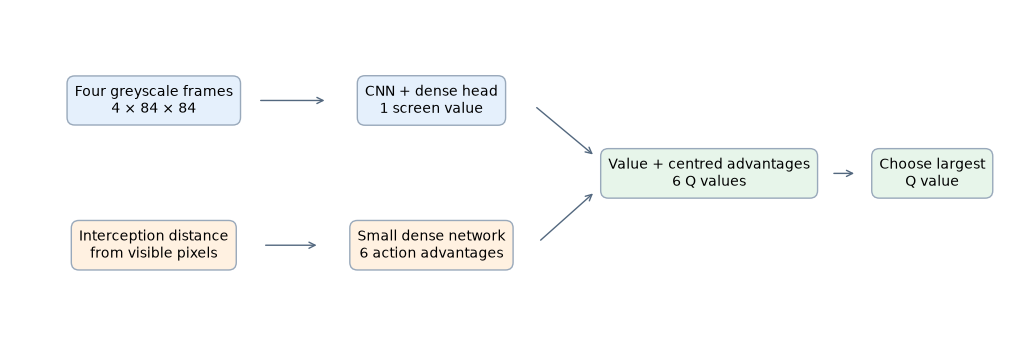

In [30]:
# Show the two sources of information that feed the six action values.
fig, ax = plt.subplots(figsize=(10, 3.3), constrained_layout=True)
ax.set(xlim=(0, 10), ylim=(0, 3))
ax.axis("off")
def draw_branch(x, y, text, colour):
    ax.text(x, y, text, ha="center", va="center", fontsize=10,
            bbox={"boxstyle": "round,pad=0.55", "facecolor": colour, "edgecolor": "#99a9bb"})
draw_branch(1.45, 2.15, "Four greyscale frames\n4 × 84 × 84", "#e5f0fc")
draw_branch(4.25, 2.15, "CNN + dense head\n1 screen value", "#e5f0fc")
draw_branch(1.45, 0.80, "Interception distance\nfrom visible pixels", "#fff1e1")
draw_branch(4.25, 0.80, "Small dense network\n6 action advantages", "#fff1e1")
draw_branch(7.05, 1.47, "Value + centred advantages\n6 Q values", "#e7f5ea")
draw_branch(9.30, 1.47, "Choose largest\nQ value", "#e7f5ea")
for start, end in [((2.5, 2.15), (3.2, 2.15)), ((2.55, .8), (3.12, .8)),
                   ((5.29, 2.1), (5.9, 1.63)), ((5.33, .83), (5.9, 1.30)),
                   ((8.28, 1.47), (8.54, 1.47))]:
    ax.annotate("", xy=end, xytext=start, arrowprops={"arrowstyle": "->", "color": "#53687f"})
fig.savefig(ROOT / "results" / "guided" / "architecture.png", dpi=150)
plt.show()

In [31]:
def guided_run_folder(root, method, seed):
    return root / "runs" / "guided" / f"{method}_seed_{seed}"


def run_guided_batch(root, until):
    """Advance every run to the same evaluation checkpoint."""
    plan = json.loads((root / "guided_plan.json").read_text(encoding="utf-8"))
    budget = plan["settings"]["total_steps"]
    if until not in plan["milestones"] or until > budget:
        raise ValueError(f"Select one of these batch endpoints: {plan['milestones']}")
    for index, seed in enumerate(plan["seeds"]):
        methods = plan["methods"] if (index + until // 10_000) % 2 == 0 else list(reversed(plan["methods"]))
        for method in methods:
            folder = guided_run_folder(root, method, seed)
            status = json.loads((folder / "status.json").read_text(encoding="utf-8"))
            if status["step"] >= until and status["status"] in {"paused", "complete"}:
                print(f"{method} seed {seed}: {until:,} decisions already saved.", flush=True)
                continue
            config = GuidedConfig(**{**plan["settings"], "method": method, "seed": seed})
            run_guided(config, folder, until)


def collect_coach_benchmark(root):
    """Measure the scripted coach at five original evaluation starts per seed."""
    path = root / "results" / "guided" / "coach_evaluations.csv"
    plan = json.loads((root / "guided_plan.json").read_text(encoding="utf-8"))
    if path.exists():
        existing = pd.read_csv(path)
        if len(existing) == 5 * len(plan["seeds"]) and not existing.duplicated(["seed", "eval_index"]).any():
            return existing
    rows = []
    for seed in plan["seeds"]:
        config = GuidedConfig(**{**plan["settings"], "seed": seed})
        results = evaluate_guided(None, config, step=0, episodes=5)
        rows.extend({"seed": seed, **row} for row in results)
        print(f"Scripted coach seed {seed}: mean {np.mean([row['score'] for row in results]):.2f}", flush=True)
    frame = pd.DataFrame(rows)
    temporary = path.with_suffix(".tmp")
    frame.to_csv(temporary, index=False)
    temporary.replace(path)
    return frame


def compare_guided(root):
    """Write one row per method and checkpoint using the same first five starts."""
    plan = json.loads((root / "guided_plan.json").read_text(encoding="utf-8"))
    output = root / "results" / "guided"
    records, per_seed = [], []
    seed_labels = ("old_20k", "old_40k", "old_100k")
    for method in plan["methods"]:
        references = {}
        histories = {}
        for seed in plan["seeds"]:
            old_path = root / "runs" / "main" / f"{method}_seed_{seed}" / "evaluations.csv"
            old = pd.read_csv(old_path)
            references[seed] = {}
            for key, step in zip(seed_labels, (20_000, 40_000, 100_000)):
                first_five = old[(old.step == step) & (old.eval_index < 5)]
                if len(first_five) != 5:
                    raise ValueError(f"Expected five reference evaluations for {method}, {seed}, {step}")
                references[seed][key] = first_five.score.mean()
            references[seed]["old_100k_full"] = old[old.step == 100_000].score.mean()
            path = guided_run_folder(root, method, seed) / "evaluations.csv"
            if path.exists():
                histories[seed] = pd.read_csv(path)
        if set(histories) != set(plan["seeds"]):
            continue
        # Compare only checkpoints all three runs for this method evaluated.
        common_steps = set.intersection(*(set(frame.step) for frame in histories.values()))
        for step in sorted(common_steps):
            scores = []
            full_scores = []
            lengths = []
            improved_seeds = 0
            wins = 0
            for seed, history in histories.items():
                full = history[history.step == step]
                first_five = full[full.eval_index < 5]
                if len(first_five) != 5 or first_five.eval_index.nunique() != 5:
                    raise ValueError("Incomplete or duplicate evaluation games at a comparison checkpoint")
                expected_seeds = [100_000 + seed * 100 + index for index in range(5)]
                if sorted(first_five.eval_seed.to_list()) != expected_seeds:
                    raise ValueError("Evaluation starts differ from the original experiment")
                average = float(first_five.score.mean())
                reference = references[seed]
                scores.append(average)
                full_scores.append(float(full.score.mean()))
                lengths.append(float(first_five.length.mean()))
                improved_seeds += int(average > reference["old_40k"])
                wins += int((first_five.score > 0).sum())
                per_seed.append({"method": method, "seed": seed, "guided_decisions": int(step),
                                 **reference, "guided_mean": average, "guided_games": len(first_five),
                                 "guided_full_mean": float(full.score.mean()), "guided_full_games": len(full),
                                 "guided_scores": ", ".join(str(int(s)) for s in first_five.score),
                                 "guided_mean_episode_decisions": float(first_five.length.mean()),
                                 "guided_truncated_games": int(first_five.truncated.sum()),
                                 "gain_vs_old_40k": average - reference["old_40k"]})
            means = {key: float(np.mean([ref[key] for ref in references.values()])) for key in (*seed_labels, "old_100k_full")}
            mean = float(np.mean(scores))
            gain = mean - means["old_40k"]
            records.append({"method": method, "guided_decisions": int(step), **means,
                            "guided_mean": mean, "guided_full_mean": float(np.mean(full_scores)),
                            "across_seed_sd": float(np.std(scores, ddof=1)), "guided_games": 5 * len(scores),
                            "guided_wins": wins, "guided_mean_episode_decisions": float(np.mean(lengths)),
                            "gain_vs_old_40k": gain, "gain_vs_old_100k": mean - means["old_100k"],
                            "improved_seeds_vs_40k": improved_seeds,
                            "practical_goal_met": bool(step > 0 and gain >= plan["improvement_points"]
                                                       and improved_seeds >= plan["minimum_improved_seeds"])})
    table = pd.DataFrame(records)
    seeds = pd.DataFrame(per_seed)
    output.mkdir(parents=True, exist_ok=True)
    table.to_csv(output / "old_vs_new.csv", index=False)
    seeds.to_csv(output / "old_vs_new_per_seed.csv", index=False)
    return table, seeds


def plot_guided_results(root, table):
    """Overlay original and guided means on one decision and score scale."""
    figure, axis = plt.subplots(figsize=(9, 4.7), constrained_layout=True)
    colours = {"dqn": "#1764ab", "double_dqn": "#c35a10"}
    labels = {"dqn": "DQN", "double_dqn": "Double DQN"}
    for method, colour in colours.items():
        rows = table[table.method == method].sort_values("guided_decisions")
        if rows.empty:
            continue
        reference = rows.iloc[0]
        axis.plot([20_000, 40_000, 100_000], [reference.old_20k, reference.old_40k, reference.old_100k],
                  color=colour, linestyle="--", marker="x", label=f"Original {labels[method]}")
        axis.plot(rows.guided_decisions, rows.guided_mean, color=colour, marker="o", label=f"Guided {labels[method]}")
    axis.set(xlabel="Training decisions per run", ylabel="Mean raw evaluation score",
             title="Original and guided Pong agents on the same five evaluation starts", ylim=(-22, 22))
    axis.axhline(0, color="#a0a0a0", linewidth=0.8)
    axis.legend(loc="upper right", frameon=False)
    axis.grid(axis="y", alpha=0.18)
    figure.savefig(root / "results" / "guided" / "old_vs_new.png", dpi=150)
    return figure


def record_guided_policy(root, method, seed):
    """Record the current learned policy with matching evaluation settings."""
    checkpoint = torch.load(guided_run_folder(root, method, seed) / "policy.pt",
                            map_location="cpu", weights_only=False)
    config = GuidedConfig(**checkpoint["config"])
    seed_everything(config.seed, config.torch_threads)
    network = GuidedQNetwork()
    network.load_state_dict(checkpoint["online"])
    path = root / "videos" / "guided" / f"{method}_seed_{seed}.mp4"
    rows = evaluate_guided(network, config, checkpoint["step"], 1, video_path=path)
    webm, gif = prepare_playback(path)
    meta = {"method": method, "training_seed": seed, "training_steps": checkpoint["step"],
            "evaluation_seed": rows[0]["eval_seed"], "full_game_score": rows[0]["score"],
            "full_game_length": rows[0]["length"], "recorded_decisions": min(900, rows[0]["length"]),
            "epsilon": config.eval_epsilon}
    write_json(path.with_suffix(".json"), meta)
    return webm, gif, meta

In [32]:
# Train only when explicitly requested. The notebook can also reopen saved results.
RUN_GUIDED_TRAINING = False
GUIDED_UNTIL = 10000
RUN_COACH_BENCHMARK = False
REFRESH_GUIDED_VIDEOS = False

if RUN_GUIDED_TRAINING:
    run_guided_batch(ROOT, GUIDED_UNTIL)
coach_path = ROOT / "results" / "guided" / "coach_evaluations.csv"
if RUN_COACH_BENCHMARK:
    collect_coach_benchmark(ROOT)
if coach_path.exists():
    coach_results = pd.read_csv(coach_path)
    display(Markdown("**Scripted coach benchmark**"))
    display(coach_results.groupby("seed").agg(mean_score=("score", "mean"), games=("score", "count")).round(2))
    print(f"Coach mean across the same 15 games: {coach_results.score.mean():.2f}")

double_dqn seed=17 step=0 evaluation=-21.00 (5 games)


double_dqn seed=17 1,000/20,000 320.1 decisions/s updates=0


double_dqn seed=17 2,000/20,000 348.0 decisions/s updates=1


double_dqn seed=17 3,000/20,000 61.3 decisions/s updates=251


double_dqn seed=17 4,000/20,000 61.6 decisions/s updates=501


double_dqn seed=17 5,000/20,000 64.0 decisions/s updates=751


... (68 outputs left out)

Scripted coach seed 43: mean -15.40


**Scripted coach benchmark**

,mean_score,games
seed,,
17,-14.0,5
29,-14.2,5
43,-15.4,5


Coach mean across the same 15 games: -14.53


,method,guided_decisions,old_20k,old_40k,old_100k_full,guided_mean,gain_vs_old_40k,across_seed_sd,improved_seeds_vs_40k
1,dqn,10000,-21.0,-20.87,-21.00,-15.87,5.0,2.12,3
3,double_dqn,10000,-21.0,-21.00,-20.97,-15.80,5.2,1.51,3


,method,seed,old_40k,guided_mean,guided_scores,guided_mean_episode_decisions,guided_truncated_games
3,dqn,17,-21.0,-17.8,"-17, -21, -19, -15, -17",3566.4,0
4,dqn,29,-21.0,-13.6,"-16, -15, -18, -8, -11",4365.8,0
5,dqn,43,-20.6,-16.2,"-8, -19, -20, -16, -18",3189.0,0
9,double_dqn,17,-21.0,-17.2,"-17, -21, -19, -12, -17",3757.8,0
10,double_dqn,29,-21.0,-14.2,"-16, -15, -18, -11, -11",4560.8,0
11,double_dqn,43,-21.0,-16.0,"-7, -19, -20, -16, -18",3135.6,0


Latest shared guided checkpoint: 10,000 decisions per run.
The practical improvement threshold is met by dqn, double_dqn.
Double DQN minus DQN at this checkpoint: +0.07 points.


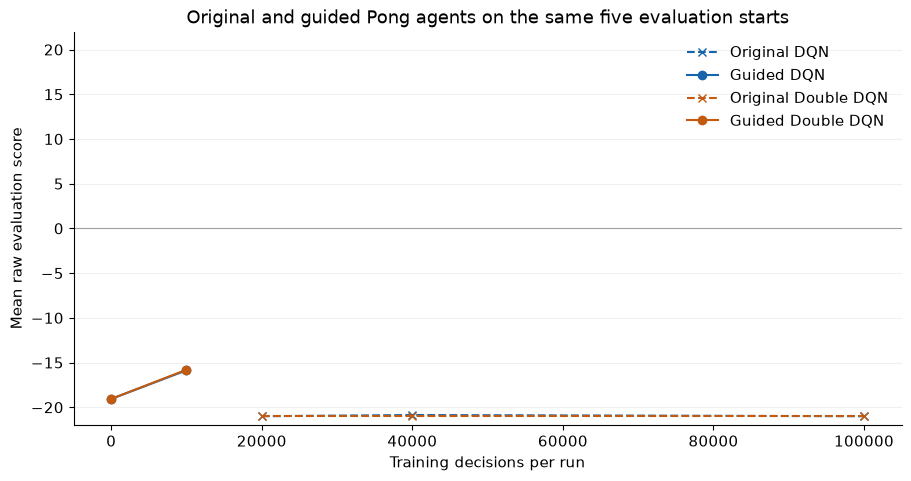

In [33]:
guided_table, guided_by_seed = compare_guided(ROOT)
if guided_table.empty:
    print("Guided evaluations will appear after the first complete batch.")
else:
    # A shared checkpoint requires rows for both methods.
    joint = guided_table.groupby("guided_decisions").method.nunique()
    shared = int(joint[joint == 2].index.max())
    latest = guided_table[guided_table.guided_decisions == shared]
    display(latest[["method", "guided_decisions", "old_20k", "old_40k", "old_100k_full",
                    "guided_mean", "gain_vs_old_40k", "across_seed_sd", "improved_seeds_vs_40k"]].round(2))
    display(guided_by_seed[guided_by_seed.guided_decisions == shared][
        ["method", "seed", "old_40k", "guided_mean", "guided_scores", "guided_mean_episode_decisions",
         "guided_truncated_games"]].round(2))
    print(f"Latest shared guided checkpoint: {shared:,} decisions per run.")
    qualified = latest[latest.practical_goal_met]
    if shared:
        if qualified.empty:
            print("The practical improvement threshold has not been reached at this checkpoint.")
        else:
            print("The practical improvement threshold is met by " + ", ".join(qualified.method) + ".")
        difference = latest.set_index("method").guided_mean
        print(f"Double DQN minus DQN at this checkpoint: {difference['double_dqn']-difference['dqn']:+.2f} points.")
    plot_guided_results(ROOT, guided_table)
    plt.show()

### Guided gameplay

The clips show the learned seed-17 policy for each method on the first shared evaluation start. Each clip displays the first 900 decisions or the whole game if it ends sooner. The caption gives the full game score from the same recording. Use the animated preview if the video player does not load. The evaluation tables include all three seeds.


**DQN, seed 17** · 10,000 decisions. The complete recorded match scored -17.

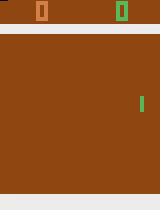

**Double DQN, seed 17** · 10,000 decisions. The complete recorded match scored -17.

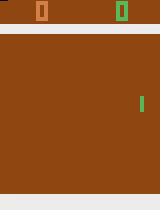

In [34]:
for method in ("dqn", "double_dqn"):
    base = ROOT / "videos" / "guided" / f"{method}_seed_17"
    metadata_path = base.with_suffix(".json")
    if REFRESH_GUIDED_VIDEOS:
        record_guided_policy(ROOT, method, 17)
    if metadata_path.exists():
        info = json.loads(metadata_path.read_text(encoding="utf-8"))
        display(Markdown(f"**{LABELS[method]}, seed 17** · {info['training_steps']:,} decisions. "
                         f"The complete recorded match scored {info['full_game_score']:+.0f}."))
        display(Video(filename=str(base.with_suffix(".webm")), mimetype="video/webm",
                      embed=True, html_attributes="controls muted preload=metadata"))
        display(Image(data=base.with_suffix(".gif").read_bytes(), format="gif"))

### What the guided results show

All six guided runs were evaluated at **10,000 decisions per run**. The comparison below uses the same first five games per training seed at each checkpoint.

- **Guided DQN** averaged **-15.87** compared with **-21.00** in the original 100k runs on those starts. Its gain over the 40k mean was **+5.00 points**, with improvement in 3 of 3 seeds and 0 wins in 15 games. Its own starting mean before any update was -19.07.
- **Guided Double DQN** averaged **-15.80** compared with **-21.00** in the original 100k runs on those starts. Its gain over the 40k mean was **+5.20 points**, with improvement in 3 of 3 seeds and 0 wins in 15 games. Its own starting mean before any update was -19.07.

The scripted coach averaged **-14.53** over the same 15 evaluation games. The starting guided scores help show how the engineered cue can affect play before training. The score comparison measures the combination of visual cue, network design and coaching. The guide depends on the colours and geometry of this Pong ROM, which limits transfer to other games.

DQN and Double DQN met the practical five-point rule, so the follow-up ended at this checkpoint. The three-seed comparison supports a descriptive conclusion about performance in these runs.

The paired comparison contains 0 truncated games. The original 100k result and the guided follow-up can both be reproduced from the checkpoint and evaluation files.